# Cannabis Consumption Trends in the United States
## 01 — Exploratory Data Analysis (EDA)

**Project:** Cannabis Consumption Trends  
**Data Source:** Monitoring the Future (MTF) — University of Michigan  
**Geographic Scope:** United States  
**Population:** Students in 8th, 10th, and 12th grades  
**Study Period:** 1975–2025  

---

### Research Objective

Investigate historical trends in cannabis consumption among U.S. students, examining changes in prevalence, consumption frequency, and differences across educational grades.

### Research Questions

1. How has cannabis consumption prevalence evolved between 1975 and 2025?
2. How do consumption patterns differ across educational grades?
3. How has the prevalence of frequent cannabis consumption changed over time?
4. What trends can be observed in cannabis vaping and related consumption categories?

### Notebook Scope

This notebook focuses on exploratory analysis, including:

- Dataset structure and variable inspection.
- Descriptive statistics.
- Historical prevalence trends.
- Comparisons across educational grades.
- Consumption frequency patterns.
- Initial observations and research findings.

Statistical hypothesis testing and advanced analyses will be conducted separately.

---

## 1. Environment Setup and Data Loading

This section initializes the Python environment and loads the processed dataset.

The dataset contains aggregated prevalence estimates from the Monitoring the Future survey.

Each observation represents a specific combination of:

- Substance or consumption category.
- Consumption reference period.
- Educational grade.
- Survey year.

**Important:** Prevalence estimates represent percentages of surveyed populations, not individual-level observations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure visualization settings
sns.set_theme(style="whitegrid")

# Define dataset location
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display basic dataset information
print(f"Total observations: {len(df)}")
print(f"Dataset dimensions: {df.shape}")
print(f"Study period: {df['year'].min()}–{df['year'].max()}")

display(df.head())

Total observations: 660
Dataset dimensions: (660, 5)
Study period: 1975–2025


,drug,time,grade,estimate,year
0,CBD,12 Month,10th Grade,11.8,2023
1,CBD,12 Month,10th Grade,8.3,2024
2,CBD,12 Month,12th Grade,15.8,2023
3,CBD,12 Month,12th Grade,13.3,2024
4,CBD,12 Month,8th Grade,5.0,2023


In [2]:
# Display all available substance categories
display(df["drug"].value_counts())

drug
Cannabis                    484
Vaping Cannabis              99
Vaping Flavored Cannabis     45
Medical Cannabis             26
CBD                           6
Name: count, dtype: int64

## 2. Dataset Structure & Data Quality

### 2.1 Dataset Overview

Before conducting exploratory analysis, it is essential to understand the dataset's structure, variable types, and completeness.

This section examines:

- Dataset dimensions and data types.
- Missing values across variables.
- Duplicate observations.
- Distribution of records across consumption categories.

**Data Quality Objective:** Verify that the processed dataset is structurally consistent and suitable for descriptive statistical analysis.

**Note:** The original datasets were previously inspected and consolidated. Three entirely empty columns (`LBYear1`, `LBYear2`, and `LBYear3`) were excluded during preprocessing.

The original CSV files remain unchanged in `data/raw/`.

In [3]:
# Inspect dataset structure
print("DATASET STRUCTURE")
print("-" * 50)

df.info()

# Calculate missing values
missing_values = df.isna().sum()

# Identify duplicate observations
duplicate_count = df.duplicated(
    subset=["drug", "time", "grade", "year"]
).sum()

# Display data quality summary
quality_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": missing_values,
    "Missing (%)": (missing_values / len(df) * 100).round(2)
})

display(quality_summary)

print(f"\nDuplicate observations: {duplicate_count}")

DATASET STRUCTURE
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   drug      660 non-null    str    
 1   time      660 non-null    str    
 2   grade     660 non-null    str    
 3   estimate  660 non-null    float64
 4   year      660 non-null    int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 25.9 KB


,Data Type,Missing Values,Missing (%)
drug,str,0,0.0
time,str,0,0.0
grade,str,0,0.0
estimate,float64,0,0.0
year,int64,0,0.0



Duplicate observations: 0


## 3. Descriptive Statistics

### 3.1 Prevalence Distribution

Descriptive statistics provide an initial understanding of cannabis consumption prevalence across the dataset.

This section examines:

- Mean and median prevalence.
- Minimum and maximum prevalence.
- Standard deviation.
- Distribution of prevalence estimates across consumption categories.

**Analytical Consideration:** Each observation represents a prevalence estimate for a specific year, grade, and consumption category. Therefore, descriptive statistics summarize the distribution of reported estimates rather than individual consumption behavior.

Comparisons between categories must account for differences in historical coverage, consumption definitions, and population groups.

In [4]:
# Calculate descriptive statistics
descriptive_stats = df.groupby("drug")["estimate"].agg(
    observations="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
).round(2)

display(descriptive_stats)

,observations,mean,median,std,minimum,maximum
drug,,,,,,
CBD,6,9.58,10.05,4.89,3.3,15.8
Cannabis,484,19.66,16.70,14.88,0.2,60.4
Medical Cannabis,26,1.78,1.65,0.65,1.0,3.6
Vaping Cannabis,99,9.94,8.40,7.38,0.2,27.9
Vaping Flavored Cannabis,45,6.05,6.10,2.77,1.4,12.1


## 4. Historical Cannabis Consumption Trends

### 4.1 Annual Cannabis Prevalence by Educational Grade

This section investigates how annual cannabis consumption prevalence has evolved among U.S. students between 1975 and 2025.

**Research Question (RQ1):**

How has past-year cannabis consumption prevalence changed over time across different educational grades?

**Primary Metric:** Past-year cannabis use prevalence (%).

**Analytical Approach:**

- Filter observations to the Cannabis category.
- Select the 12-month consumption reference period.
- Compare historical trends across 8th, 10th, and 12th grades.
- Identify periods of increasing or decreasing prevalence.

**Methodological Considerations:**

The 12th-grade survey began in 1975, while 8th- and 10th-grade surveys were introduced in 1991.

Consequently, comparisons involving all three grades must be restricted to 1991 onward.

Prevalence estimates are reported percentages and should not be interpreted as absolute numbers of cannabis users.

In [5]:
# Filter past-year cannabis prevalence observations
annual_cannabis = df[
    (df["drug"] == "Cannabis") &
    (df["time"] == "12 Month")
].copy()

# Sort observations chronologically
annual_cannabis = annual_cannabis.sort_values(
    ["grade", "year"]
)

# Summarize temporal coverage by grade
coverage_summary = annual_cannabis.groupby("grade").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    observations=("estimate", "count")
)

display(coverage_summary)

# Preview the filtered dataset
display(annual_cannabis.head())

,first_year,last_year,observations
grade,,,
10th Grade,1991,2025,35
12th Grade,1975,2025,51
8th Grade,1991,2025,35


,drug,time,grade,estimate,year
6,Cannabis,12 Month,10th Grade,16.5,1991
7,Cannabis,12 Month,10th Grade,15.2,1992
8,Cannabis,12 Month,10th Grade,19.2,1993
9,Cannabis,12 Month,10th Grade,25.2,1994
10,Cannabis,12 Month,10th Grade,28.7,1995


### 4.2 Historical Prevalence Visualization

The following visualization examines changes in past-year cannabis use prevalence among U.S. students from 1975 to 2025.

**Visualization Objectives:**

- Identify long-term consumption trends.
- Compare prevalence across educational grades.
- Detect historical peaks and declines.
- Examine differences between age groups.

**Metric:** Past-year cannabis use prevalence (%).

**Source:** Monitoring the Future — University of Michigan.

The visualization preserves the original survey estimates without interpolation or smoothing.

findfont: Failed to find font weight bold for Bahnschrift, now using 400.
findfont: Failed to find font weight bold for Bahnschrift, now using 400.


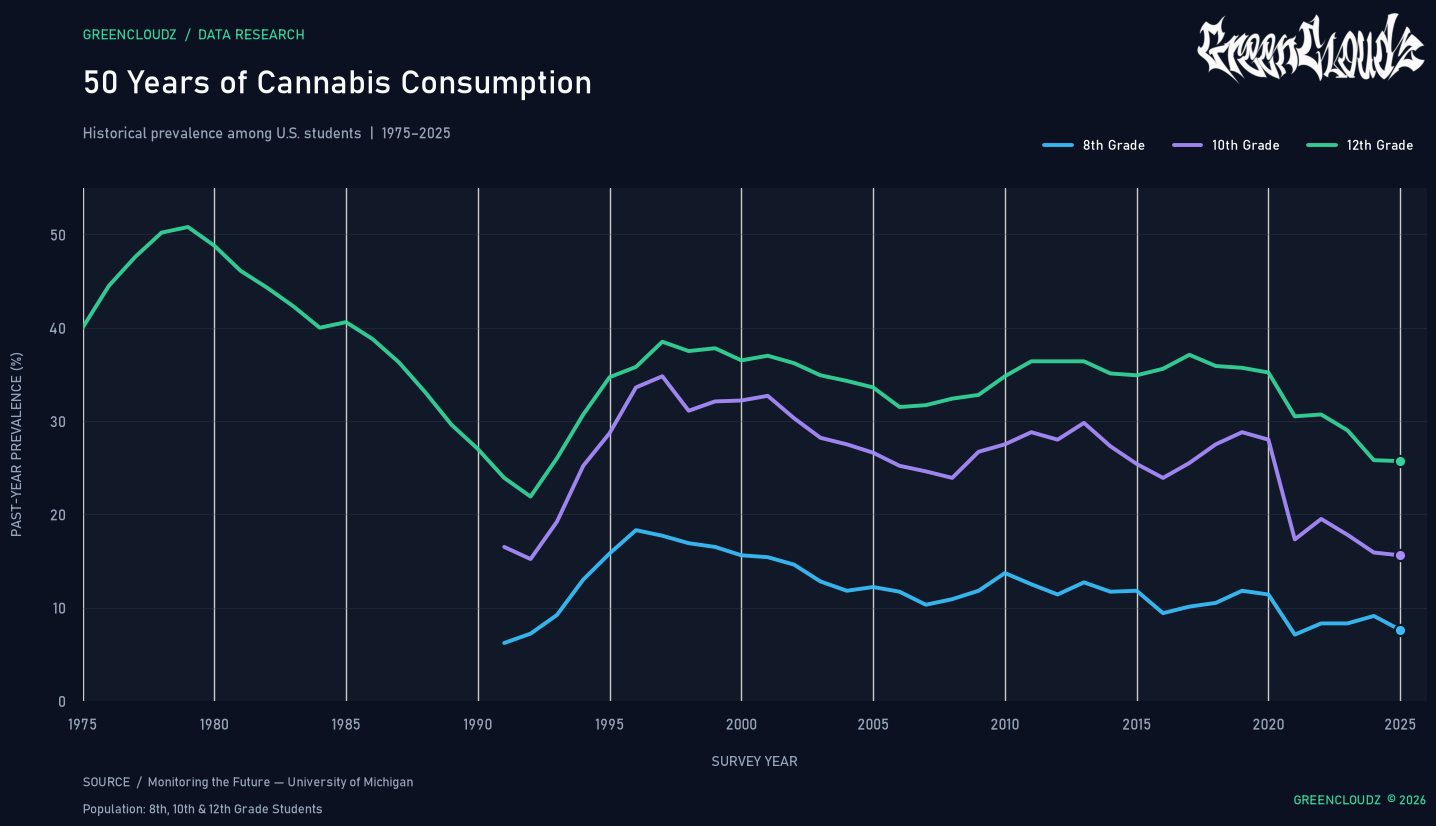

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "blue": "#38BDF8",
    "purple": "#A78BFA",
    "green": "#34D399"
}

GRADE_COLORS = {
    "8th Grade": COLORS["blue"],
    "10th Grade": COLORS["purple"],
    "12th Grade": COLORS["green"]
}

# Select a professional font
available_fonts = {font.name for font in fm.fontManager.ttflist}

FONT_FAMILY = next(
    (
        font for font in [
            "Montserrat",
            "Bahnschrift",
            "Aptos",
            "DejaVu Sans"
        ]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "savefig.facecolor": COLORS["background"]
})

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig = plt.figure(
    figsize=(16, 9),
    facecolor=COLORS["background"]
)

ax = fig.add_axes(
    [0.09, 0.19, 0.84, 0.57],
    facecolor=COLORS["panel"]
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.09, 0.925,
    "GREENCLOUDZ  /  DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["green"],
    tracking=None
) if False else None

fig.text(
    0.09, 0.925,
    "GREENCLOUDZ  /  DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["green"]
)

fig.text(
    0.09, 0.865,
    "50 Years of Cannabis Consumption",
    fontsize=24,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.09, 0.815,
    "Historical prevalence among U.S. students  |  1975–2025",
    fontsize=11,
    color=COLORS["muted"]
)

# --------------------------------------------------
# HISTORICAL DATA
# --------------------------------------------------

for grade in ["8th Grade", "10th Grade", "12th Grade"]:

    group = annual_cannabis[
        annual_cannabis["grade"] == grade
    ].sort_values("year")

    ax.plot(
        group["year"],
        group["estimate"],
        label=grade,
        color=GRADE_COLORS[grade],
        linewidth=2.8,
        alpha=0.95,
        solid_capstyle="round",
        zorder=3
    )

    # Highlight the latest observation
    latest = group.iloc[-1]

    ax.scatter(
        latest["year"],
        latest["estimate"],
        color=GRADE_COLORS[grade],
        s=65,
        edgecolors=COLORS["panel"],
        linewidths=1.5,
        zorder=5
    )

# --------------------------------------------------
# AXIS STYLING
# --------------------------------------------------

ax.set_xlim(1975, 2026)
ax.set_ylim(0, 55)

ax.set_xticks(range(1975, 2026, 5))

ax.set_ylabel(
    "PAST-YEAR PREVALENCE (%)",
    fontsize=10,
    fontweight="bold",
    labelpad=18
)

ax.set_xlabel(
    "SURVEY YEAR",
    fontsize=10,
    fontweight="bold",
    labelpad=16
)

ax.grid(
    axis="y",
    color=COLORS["grid"],
    alpha=0.35,
    linewidth=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    pad=12
)

# --------------------------------------------------
# LEGEND
# --------------------------------------------------

legend = ax.legend(
    loc="upper right",
    ncol=3,
    frameon=False,
    fontsize=10,
    labelcolor=COLORS["text"],
    bbox_to_anchor=(1, 1.12)
)

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.785,
        0.87,
        0.145,
        0.09
    ])

    logo_ax.imshow(logo)
    logo_ax.set_aspect("equal")
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.09, 0.095,
    "SOURCE  /  Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.09, 0.065,
    "Population: 8th, 10th & 12th Grade Students",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.93, 0.075,
    "GREENCLOUDZ  © 2026",
    fontsize=9,
    color=COLORS["green"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "historical_cannabis_prevalence.png",
    dpi=300,
    facecolor=fig.get_facecolor()
)

from IPython.display import display, HTML

# Center the notebook visualization
display(HTML("""
<style>
.jp-OutputArea-output img {
    display: block;
    margin-left: auto;
    margin-right: auto;
}
</style>
"""))

plt.show()

### 4.3 Historical Peaks and Minimum Prevalence

This section identifies the highest and lowest recorded past-year cannabis prevalence estimates for each educational grade.

**Analytical Objectives:**

- Identify historical peak prevalence and its corresponding year.
- Determine the lowest recorded prevalence for each grade.
- Quantify the difference between historical maximum and minimum values.
- Compare the magnitude of historical fluctuations across educational grades.

**Metrics:**

- Maximum prevalence (%).
- Minimum prevalence (%).
- Prevalence range (percentage points).

**Methodological Note:** Historical extrema are calculated from observed survey estimates. They do not necessarily represent statistically significant differences.

In [7]:
# Identify historical maximum and minimum prevalence by grade
historical_extremes = []

for grade, group in annual_cannabis.groupby("grade"):

    peak = group.loc[group["estimate"].idxmax()]
    minimum = group.loc[group["estimate"].idxmin()]

    historical_extremes.append({
        "Grade": grade,
        "Peak Year": int(peak["year"]),
        "Peak Prevalence (%)": peak["estimate"],
        "Minimum Year": int(minimum["year"]),
        "Minimum Prevalence (%)": minimum["estimate"],
        "Range (pp)": round(
            peak["estimate"] - minimum["estimate"], 2
        )
    })

historical_extremes_df = pd.DataFrame(
    historical_extremes
).sort_values("Grade")

display(historical_extremes_df)

,Grade,Peak Year,Peak Prevalence (%),Minimum Year,Minimum Prevalence (%),Range (pp)
0,10th Grade,1997,34.8,1992,15.2,19.6
1,12th Grade,1979,50.8,1992,21.9,28.9
2,8th Grade,1996,18.3,1991,6.2,12.1


### 4.4 Preliminary Historical Findings

The analysis of historical prevalence estimates reveals several notable patterns.

**Finding 1 — Historical peak among 12th-grade students**

The highest recorded past-year cannabis prevalence was 50.8% in 1979 among 12th-grade students.

The lowest recorded prevalence for this group was 21.9% in 1992, representing a historical range of 28.9 percentage points.

**Finding 2 — Peak prevalence during the 1990s**

Unlike 12th-grade students, the highest recorded prevalence among younger students occurred during the 1990s:

- 8th Grade: 18.3% in 1996.
- 10th Grade: 34.8% in 1997.

**Finding 3 — Differences in historical coverage**

The 12th-grade series covers 1975–2025, whereas the 8th- and 10th-grade series begin in 1991.

Consequently, historical ranges are not directly comparable across all three grades without restricting the analysis to a common observation period.

**Research Implication**

These findings suggest that cannabis consumption prevalence has experienced substantial historical fluctuations.

Further analysis is required to quantify long-term changes and determine whether recent prevalence estimates differ meaningfully from historical observations.

**Limitation:** The reported values are survey estimates. Differences between historical estimates should not automatically be interpreted as statistically significant.

### 4.5 Long-Term Prevalence Change (1991–2025)

This section quantifies changes in past-year cannabis use prevalence across educational grades over a common observation period.

**Research Question:**

How did cannabis consumption prevalence change between 1991 and 2025 among 8th-, 10th-, and 12th-grade students?

**Metrics:**

- **Baseline Prevalence (%):** Estimated prevalence in 1991.
- **Final Prevalence (%):** Estimated prevalence in 2025.
- **Absolute Change (pp):** Difference between final and baseline prevalence, expressed in percentage points.
- **Relative Change (%):** Percentage change relative to the baseline value.

**Formulas:**

Absolute Change = Final Prevalence − Baseline Prevalence

Relative Change = (Absolute Change / Baseline Prevalence) × 100

**Methodological Consideration:**

The 1991–2025 period is selected because all three educational grades have available observations throughout this interval.

Absolute and relative changes describe differences between survey estimates. They do not establish statistical significance or causality.

In [8]:
# Define the common comparison period
BASELINE_YEAR = 1991
FINAL_YEAR = 2025

# Select baseline and final observations
comparison_data = annual_cannabis[
    annual_cannabis["year"].isin([BASELINE_YEAR, FINAL_YEAR])
].copy()

# Reshape data for historical comparison
historical_comparison = comparison_data.pivot(
    index="grade",
    columns="year",
    values="estimate"
)

# Rename columns
historical_comparison = historical_comparison.rename(
    columns={
        BASELINE_YEAR: "Baseline Prevalence (%)",
        FINAL_YEAR: "Final Prevalence (%)"
    }
)

# Calculate absolute change in percentage points
historical_comparison["Absolute Change (pp)"] = (
    historical_comparison["Final Prevalence (%)"]
    - historical_comparison["Baseline Prevalence (%)"]
)

# Calculate relative percentage change
historical_comparison["Relative Change (%)"] = (
    historical_comparison["Absolute Change (pp)"]
    / historical_comparison["Baseline Prevalence (%)"]
) * 100

# Organize educational grades
grade_order = ["8th Grade", "10th Grade", "12th Grade"]

historical_comparison = historical_comparison.reindex(grade_order)

# Display results
display(historical_comparison.round(2))

year,Baseline Prevalence (%),Final Prevalence (%),Absolute Change (pp),Relative Change (%)
grade,,,,
8th Grade,6.2,7.6,1.4,22.58
10th Grade,16.5,15.6,-0.9,-5.45
12th Grade,23.9,25.7,1.8,7.53


### 4.6 Long-Term Prevalence Change: Key Findings

The comparison between 1991 and 2025 reveals relatively modest net changes in past-year cannabis use prevalence across educational grades.

**8th Grade**
- Baseline prevalence (1991): 6.2%.
- Final prevalence (2025): 7.6%.
- Absolute change: +1.4 percentage points.
- Relative change: +22.58%.

**10th Grade**
- Baseline prevalence (1991): 16.5%.
- Final prevalence (2025): 15.6%.
- Absolute change: −0.9 percentage points.
- Relative change: −5.45%.

**12th Grade**
- Baseline prevalence (1991): 23.9%.
- Final prevalence (2025): 25.7%.
- Absolute change: +1.8 percentage points.
- Relative change: +7.53%.

**Key Finding**

Despite substantial fluctuations throughout the observation period, past-year cannabis use prevalence in 2025 remained relatively close to its 1991 level across all three educational grades.

**Interpretation**

These results highlight the importance of distinguishing long-term net changes from fluctuations occurring within the observation period.

A comparison of two endpoints alone cannot fully describe the historical evolution of cannabis consumption.

**Limitation**

The calculated changes describe differences between survey estimates and do not establish statistical significance.

## 5. Cannabis Consumption Frequency Analysis

### 5.1 Consumption Frequency Overview

This section examines how cannabis use prevalence varies across different reporting intervals.

**Research Question (RQ2):**

How have different patterns of cannabis consumption evolved among U.S. students?

**Consumption Indicators:**

- **Lifetime:** Percentage of students who have used cannabis at least once in their lifetime.
- **12 Month:** Percentage reporting cannabis use within the past year.
- **30 Day:** Percentage reporting cannabis use within the past month.
- **Daily:** Percentage reporting daily or near-daily cannabis use, according to the survey definition.

**Analytical Objectives:**

1. Compare consumption prevalence across reporting intervals.
2. Identify historical trends in frequent cannabis use.
3. Examine differences across educational grades.
4. Determine whether frequent consumption follows the same historical patterns as overall consumption.

**Methodological Considerations:**

These indicators measure overlapping populations and must not be added together.

Prevalence estimates describe population-level consumption patterns rather than individual consumption frequency.

Comparisons across all three educational grades will focus on the common observation period of 1991–2025.

In [9]:
import pandas as pd

from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter cannabis consumption observations
cannabis_frequency = df[
    df["drug"] == "Cannabis"
].copy()

# Define consumption indicators
frequency_order = [
    "Lifetime",
    "12 Month",
    "30 Day",
    "Daily"
]

# Summarize data availability
frequency_coverage = (
    cannabis_frequency
    .groupby(["time", "grade"])
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("estimate", "count")
    )
    .reset_index()
)

# Organize indicators chronologically
frequency_coverage["time"] = pd.Categorical(
    frequency_coverage["time"],
    categories=frequency_order,
    ordered=True
)

frequency_coverage = frequency_coverage.sort_values(
    ["time", "grade"]
)

display(frequency_coverage)

,time,grade,first_year,last_year,observations
9,Lifetime,10th Grade,1991,2025,35
10,Lifetime,12th Grade,1975,2025,51
11,Lifetime,8th Grade,1991,2025,35
0,12 Month,10th Grade,1991,2025,35
1,12 Month,12th Grade,1975,2025,51
2,12 Month,8th Grade,1991,2025,35
3,30 Day,10th Grade,1991,2025,35
4,30 Day,12th Grade,1975,2025,51
5,30 Day,8th Grade,1991,2025,35
6,Daily,10th Grade,1991,2025,35


### 5.2 Historical Trends by Consumption Indicator

This visualization compares four cannabis use prevalence indicators across educational grades.

**Research Objective:** Determine whether lifetime, past-year, past-month, and daily cannabis use prevalence follow similar historical patterns.

**Visualization Design:**

- One panel per educational grade.
- Four prevalence indicators per panel.
- Common observation period: 1991–2025.
- Consistent colors and percentage scales across panels.

**Methodological Note:** Reporting intervals represent overlapping populations. Differences between indicators should not be interpreted as mutually exclusive consumption groups.

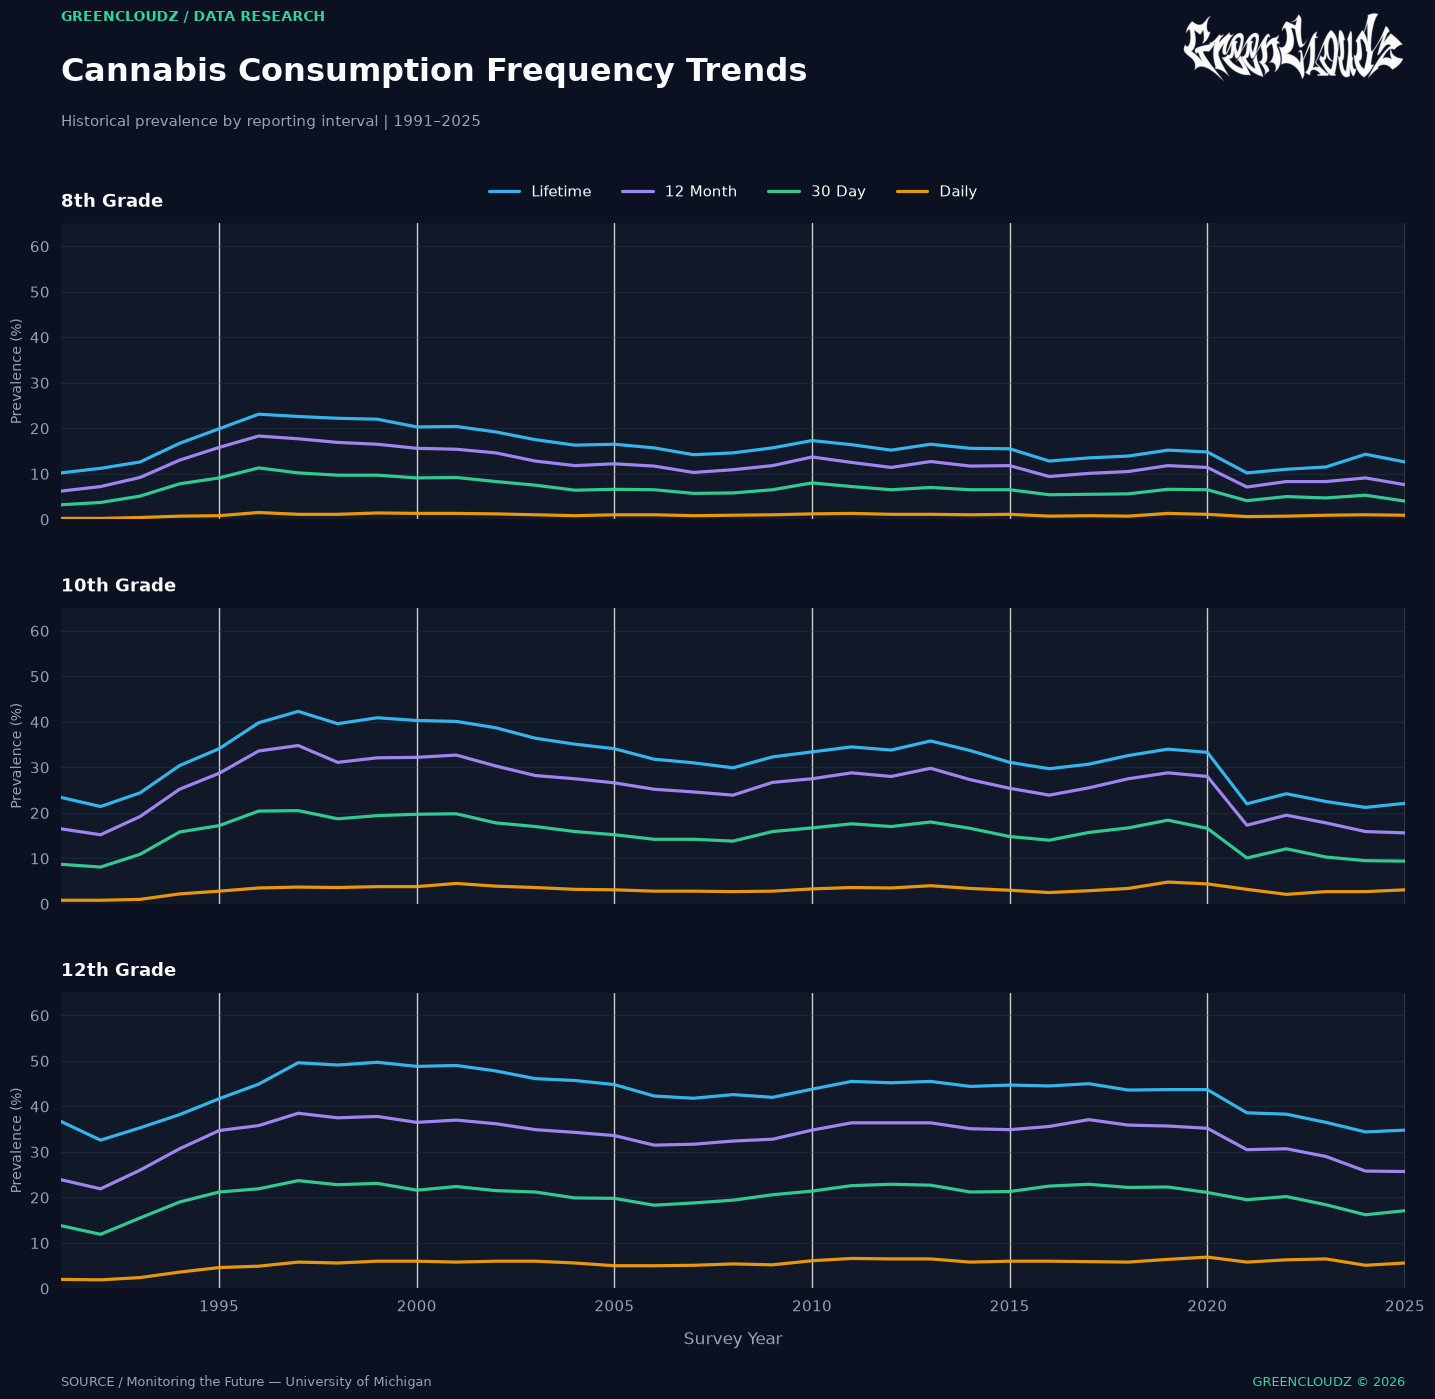

In [10]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# Define Greencloudz visual identity
COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "green": "#34D399"
}

FREQUENCY_COLORS = {
    "Lifetime": "#38BDF8",
    "12 Month": "#A78BFA",
    "30 Day": "#34D399",
    "Daily": "#F59E0B"
}

# Select available font
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# Load processed dataset
df = pd.read_csv(
    "../data/processed/cannabis_prevalence_clean.csv"
)

# Filter comparable observations
frequency_data = df[
    (df["drug"] == "Cannabis") &
    (df["year"].between(1991, 2025))
].copy()

grades = ["8th Grade", "10th Grade", "12th Grade"]

# Create independent panels
fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 15),
    sharex=True,
    sharey=True,
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.09,
    right=0.93,
    top=0.82,
    bottom=0.11,
    hspace=0.30
)

# Add figure header
fig.text(
    0.09, 0.955,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["green"]
)

fig.text(
    0.09, 0.915,
    "Cannabis Consumption Frequency Trends",
    fontsize=23,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.09, 0.885,
    "Historical prevalence by reporting interval | 1991–2025",
    fontsize=11,
    color=COLORS["muted"]
)

# Plot each educational grade
for ax, grade in zip(axes, grades):

    ax.set_facecolor(COLORS["panel"])

    grade_data = frequency_data[
        frequency_data["grade"] == grade
    ]

    for interval, color in FREQUENCY_COLORS.items():

        series = grade_data[
            grade_data["time"] == interval
        ].sort_values("year")

        ax.plot(
            series["year"],
            series["estimate"],
            label=interval,
            color=color,
            linewidth=2.3,
            alpha=0.95
        )

    ax.set_title(
        grade,
        loc="left",
        fontsize=13,
        fontweight="bold",
        color=COLORS["text"],
        pad=12
    )

    ax.set_ylabel("Prevalence (%)", fontsize=10)

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        alpha=0.35
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(axis="both", length=0, pad=8)

    ax.set_ylim(0, 65)

# Configure shared timeline
axes[-1].set_xlim(1991, 2025)
axes[-1].set_xticks(range(1995, 2026, 5))
axes[-1].set_xlabel("Survey Year", labelpad=12)

# Add shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.51, 0.855),
    ncol=4,
    frameon=False,
    labelcolor=COLORS["text"]
)

# Add Greencloudz logo
logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():
    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([0.79, 0.90, 0.14, 0.075])
    logo_ax.imshow(logo)
    logo_ax.axis("off")

# Add source information
fig.text(
    0.09, 0.045,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.93, 0.045,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["green"],
    ha="right"
)

# Export visualization
output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "cannabis_consumption_frequency_trends.png",
    dpi=300,
    facecolor=COLORS["background"],
    bbox_inches="tight"
)

plt.show()

## 6. Medical Cannabis Consumption Analysis

### 6.1 Historical Prevalence Trends (2017–2025)

**Research Question:**

How has the reported prevalence of medical cannabis use evolved among U.S. students between 2017 and 2025?

**Analytical Objectives:**

- Examine historical prevalence trends by educational grade.
- Identify differences between student populations.
- Quantify changes in reported medical cannabis use.
- Identify historical peaks and declines.

**Available Indicator:** Lifetime prevalence.

**Methodological Considerations:**

- Medical cannabis data are available from 2017 onward.
- The dataset contains one missing observation for 12th-grade students in 2020.
- Missing observations will not be interpolated or replaced.
- Lifetime prevalence measures reported use at least once, not current medical cannabis consumption.

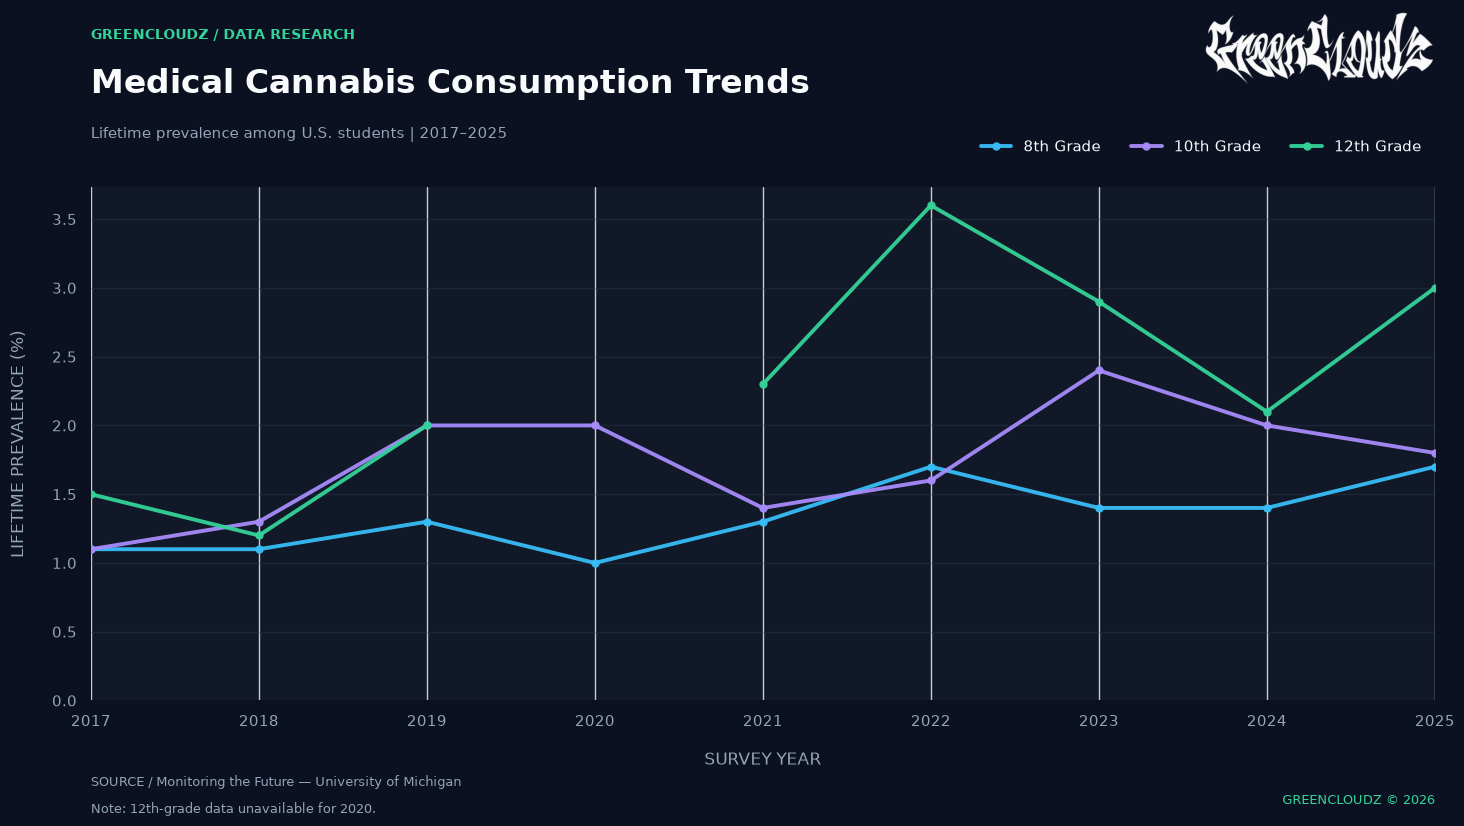

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# Load processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Filter medical cannabis observations
medical_cannabis = df[
    (df["drug"] == "Medical Cannabis") &
    (df["time"] == "Lifetime")
].copy()

# Define Greencloudz color palette
COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

GRADE_COLORS = {
    "8th Grade": "#38BDF8",
    "10th Grade": "#A78BFA",
    "12th Grade": "#34D399"
}

# Configure typography
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# Create figure
fig = plt.figure(
    figsize=(16, 9),
    facecolor=COLORS["background"]
)

ax = fig.add_axes(
    [0.09, 0.19, 0.84, 0.57],
    facecolor=COLORS["panel"]
)

# Add header
fig.text(
    0.09, 0.925,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.09, 0.865,
    "Medical Cannabis Consumption Trends",
    fontsize=24,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.09, 0.815,
    "Lifetime prevalence among U.S. students | 2017–2025",
    fontsize=11,
    color=COLORS["muted"]
)

# Plot prevalence by grade
for grade, color in GRADE_COLORS.items():

    series = medical_cannabis[
        medical_cannabis["grade"] == grade
    ].sort_values("year")

    # Preserve missing survey years without interpolation
    complete_years = pd.DataFrame({
        "year": range(2017, 2026)
    })

    series = complete_years.merge(
        series[["year", "estimate"]],
        on="year",
        how="left"
    )

    ax.plot(
        series["year"],
        series["estimate"],
        label=grade,
        color=color,
        linewidth=2.8,
        marker="o",
        markersize=5,
        alpha=0.95
    )

# Configure axes
ax.set_xlim(2017, 2025)
ax.set_xticks(range(2017, 2026))

ax.set_ylim(bottom=0)

ax.set_xlabel("SURVEY YEAR", labelpad=16)
ax.set_ylabel("LIFETIME PREVALENCE (%)", labelpad=18)

ax.grid(
    axis="y",
    color=COLORS["grid"],
    alpha=0.35
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="both", length=0, pad=10)

# Configure legend
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1, 1.12),
    ncol=3,
    frameon=False,
    labelcolor=COLORS["text"]
)

# Add Greencloudz logo
logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():
    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.785, 0.87, 0.145, 0.09
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# Add footer
fig.text(
    0.09, 0.095,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.09, 0.065,
    "Note: 12th-grade data unavailable for 2020.",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.93, 0.075,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# Export visualization
output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "medical_cannabis_prevalence.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

### 6.2 Medical Cannabis: Historical Change Assessment

This section quantifies changes in lifetime medical cannabis use prevalence between 2017 and 2025.

**Analytical Objectives:**

- Calculate absolute prevalence changes in percentage points.
- Calculate relative percentage changes.
- Identify historical maximum and minimum prevalence.
- Compare changes across educational grades.

**Metrics:**

- Baseline prevalence (2017).
- Final prevalence (2025).
- Absolute change (percentage points).
- Relative change (%).
- Historical maximum and minimum prevalence.

**Methodological Considerations:**

The analysis uses aggregated survey estimates rather than individual-level observations.

Changes in prevalence do not necessarily indicate statistically significant differences.

The missing 2020 observation for 12th-grade students will be excluded without interpolation.

In [12]:
import pandas as pd
from pathlib import Path

# Load processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter medical cannabis observations
medical_data = df[
    (df["drug"] == "Medical Cannabis") &
    (df["time"] == "Lifetime")
].copy()

# Define comparison years
BASELINE_YEAR = 2017
FINAL_YEAR = 2025

# Calculate historical metrics
results = []

for grade, group in medical_data.groupby("grade"):

    group = group.sort_values("year")

    baseline = group.loc[
        group["year"] == BASELINE_YEAR, "estimate"
    ].iloc[0]

    final = group.loc[
        group["year"] == FINAL_YEAR, "estimate"
    ].iloc[0]

    peak = group.loc[group["estimate"].idxmax()]
    minimum = group.loc[group["estimate"].idxmin()]

    absolute_change = final - baseline
    relative_change = (absolute_change / baseline) * 100

    results.append({
        "Grade": grade,
        "2017 Prevalence (%)": baseline,
        "2025 Prevalence (%)": final,
        "Absolute Change (pp)": absolute_change,
        "Relative Change (%)": relative_change,
        "Peak Year": int(peak["year"]),
        "Peak Prevalence (%)": peak["estimate"],
        "Minimum Year": int(minimum["year"]),
        "Minimum Prevalence (%)": minimum["estimate"]
    })

# Create results table
medical_summary = pd.DataFrame(results)

# Sort educational grades
grade_order = ["8th Grade", "10th Grade", "12th Grade"]

medical_summary["Grade"] = pd.Categorical(
    medical_summary["Grade"],
    categories=grade_order,
    ordered=True
)

medical_summary = medical_summary.sort_values("Grade")

display(medical_summary.round(2))

,Grade,2017 Prevalence (%),2025 Prevalence (%),Absolute Change (pp),Relative Change (%),Peak Year,Peak Prevalence (%),Minimum Year,Minimum Prevalence (%)
2,8th Grade,1.1,1.7,0.6,54.55,2022,1.7,2020,1.0
0,10th Grade,1.1,1.8,0.7,63.64,2023,2.4,2017,1.1
1,12th Grade,1.5,3.0,1.5,100.00,2022,3.6,2018,1.2


### 6.3 Medical Cannabis: Key Findings

The analysis of lifetime medical cannabis use prevalence between 2017 and 2025 reveals increases across all three educational grades.

**Finding 1 — Prevalence increased across all grades**

- 8th Grade: 1.1% to 1.7% (+0.6 percentage points).
- 10th Grade: 1.1% to 1.8% (+0.7 percentage points).
- 12th Grade: 1.5% to 3.0% (+1.5 percentage points).

**Finding 2 — Largest absolute increase among 12th-grade students**

Lifetime medical cannabis prevalence doubled among 12th-grade students, representing a relative increase of 100%.

Despite this substantial relative change, the absolute increase was 1.5 percentage points.

**Finding 3 — Historical prevalence peaks**

The highest recorded prevalence estimates occurred in:

- 8th Grade: 1.7% in 2022.
- 10th Grade: 2.4% in 2023.
- 12th Grade: 3.6% in 2022.

**Interpretation**

The observed increases suggest that lifetime medical cannabis use became more prevalent among surveyed students between 2017 and 2025.

However, the findings do not establish whether these changes were statistically significant.

**Limitations**

- Lifetime prevalence does not measure current or regular consumption.
- The 12th-grade observation for 2020 is unavailable.
- Relative increases can appear substantial when baseline prevalence is low.
- The analysis cannot establish whether changes in medical cannabis legislation caused the observed trends.

## 7. Cannabis Vaping Trends

### 7.1 Dataset Overview and Historical Coverage

This section investigates the evolution of cannabis vaping prevalence among U.S. students.

**Research Question (RQ3):**

How has cannabis vaping prevalence evolved across educational grades, and how do trends differ by consumption reporting interval?

**Analytical Objectives:**

1. Examine historical trends in cannabis vaping prevalence.
2. Compare lifetime, past-year, past-month, and daily use.
3. Identify differences across educational grades.
4. Quantify historical changes and identify prevalence peaks.

**Available Reporting Intervals:**

| Indicator | Available Period |
|---|---|
| Lifetime | 2017–2025 |
| 12 Month | 2017–2025 |
| 30 Day | 2017–2025 |
| Daily | 2020–2025 |

**Methodological Considerations:**

- Cannabis vaping refers to a specific method of cannabis consumption.
- Reporting intervals represent overlapping populations.
- Daily vaping data begin in 2020 and must not be treated as available before that year.
- Changes in survey estimates do not necessarily represent statistically significant differences.
- Differences in historical coverage must be considered when comparing indicators.

In [13]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter cannabis vaping observations
vaping_data = df[
    df["drug"] == "Vaping Cannabis"
].copy()

# Define reporting interval order
interval_order = [
    "Lifetime",
    "12 Month",
    "30 Day",
    "Daily"
]

# Summarize historical coverage
vaping_coverage = (
    vaping_data
    .groupby(["time", "grade"])
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("estimate", "count"),
        minimum_prevalence=("estimate", "min"),
        maximum_prevalence=("estimate", "max")
    )
    .reset_index()
)

# Organize reporting intervals
vaping_coverage["time"] = pd.Categorical(
    vaping_coverage["time"],
    categories=interval_order,
    ordered=True
)

vaping_coverage = vaping_coverage.sort_values(
    ["time", "grade"]
)

display(vaping_coverage.round(2))

,time,grade,first_year,last_year,observations,minimum_prevalence,maximum_prevalence
9,Lifetime,10th Grade,2017,2025,9,9.8,22.7
10,Lifetime,12th Grade,2017,2025,9,11.9,27.9
11,Lifetime,8th Grade,2017,2025,9,4.0,10.2
0,12 Month,10th Grade,2017,2025,9,8.1,19.4
1,12 Month,12th Grade,2017,2025,9,9.5,22.1
2,12 Month,8th Grade,2017,2025,9,3.0,8.1
3,30 Day,10th Grade,2017,2025,9,4.3,12.6
4,30 Day,12th Grade,2017,2025,9,4.9,14.8
5,30 Day,8th Grade,2017,2025,9,1.6,4.2
6,Daily,10th Grade,2020,2025,6,0.9,1.3


### 7.2 Cannabis Vaping Prevalence Trends

This visualization examines historical cannabis vaping prevalence across four reporting intervals.

**Research Objectives:**

- Compare cannabis vaping prevalence across educational grades.
- Examine differences between lifetime, past-year, past-month, and daily use.
- Identify periods of increasing or decreasing prevalence.
- Investigate whether daily vaping follows the same trends as other reporting intervals.

**Visualization Structure:**

- Lifetime prevalence: 2017–2025.
- Past-year prevalence: 2017–2025.
- Past-month prevalence: 2017–2025.
- Daily prevalence: 2020–2025.

**Methodological Note:**

All panels display prevalence estimates using a consistent percentage scale. Reporting intervals represent overlapping populations and should not be interpreted as independent groups.

Daily vaping data are only available from 2020 onward.

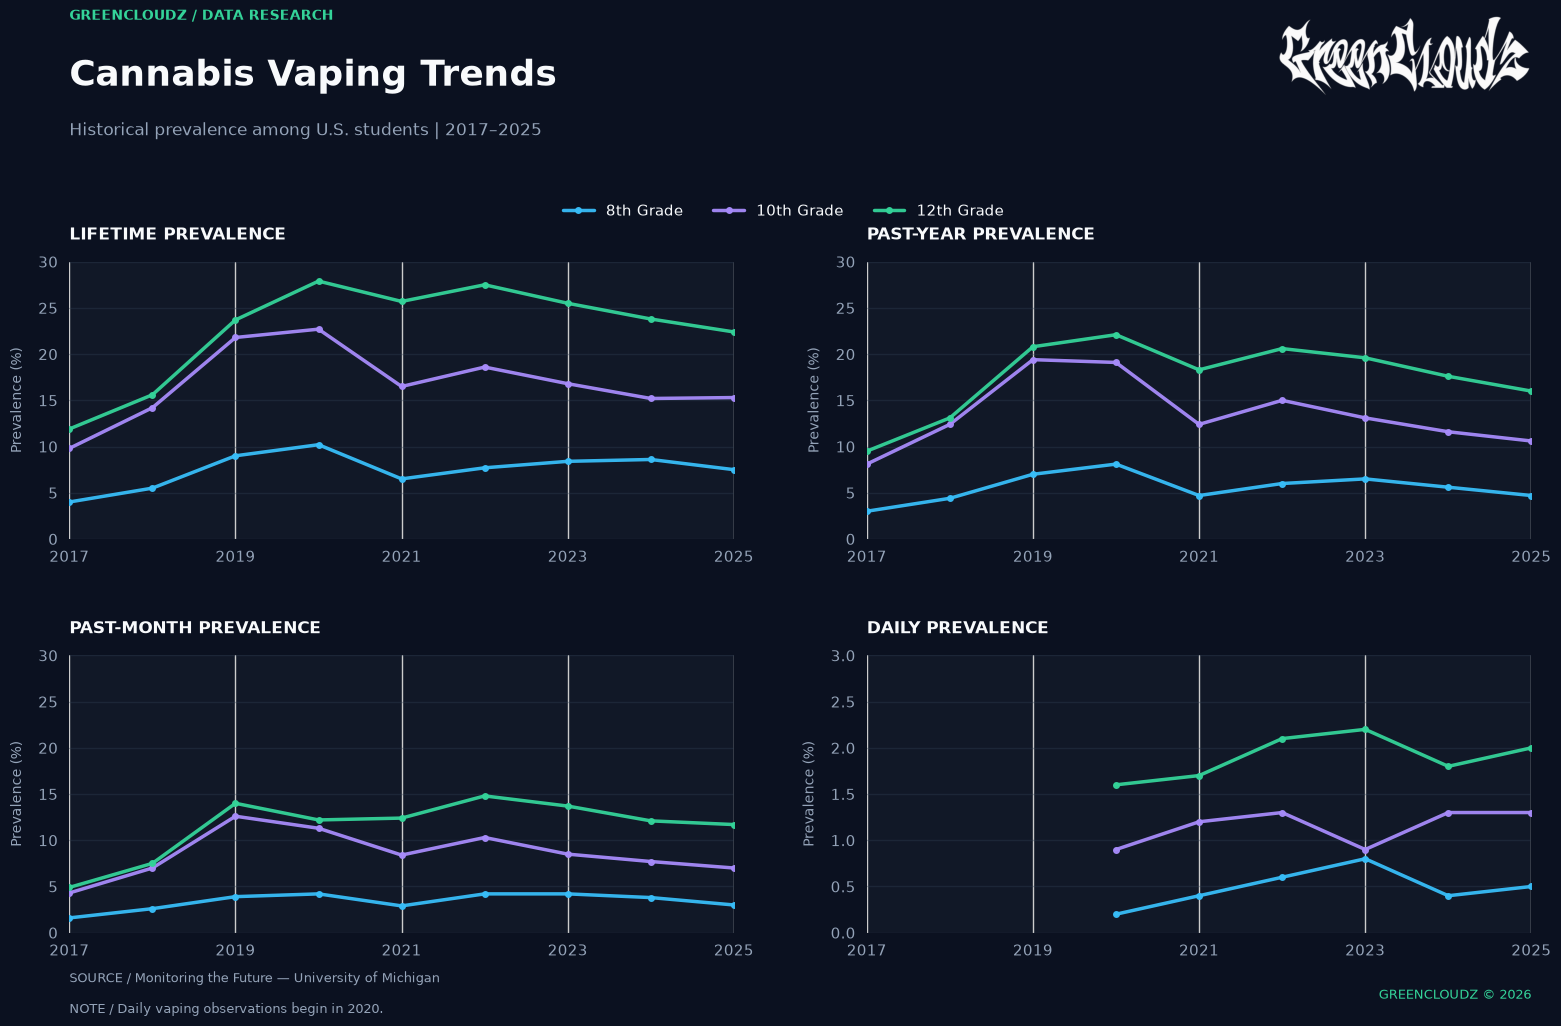

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

GRADE_COLORS = {
    "8th Grade": "#38BDF8",
    "10th Grade": "#A78BFA",
    "12th Grade": "#34D399"
}

# Configure typography
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path(
    "../data/processed/cannabis_prevalence_clean.csv"
)

df = pd.read_csv(DATA_PATH)

vaping_data = df[
    df["drug"] == "Vaping Cannabis"
].copy()

intervals = [
    "Lifetime",
    "12 Month",
    "30 Day",
    "Daily"
]

grades = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

interval_titles = {
    "Lifetime": "LIFETIME PREVALENCE",
    "12 Month": "PAST-YEAR PREVALENCE",
    "30 Day": "PAST-MONTH PREVALENCE",
    "Daily": "DAILY PREVALENCE"
}

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 11),
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.08,
    right=0.94,
    top=0.73,
    bottom=0.12,
    hspace=0.42,
    wspace=0.20
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.08, 0.95,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.08, 0.89,
    "Cannabis Vaping Trends",
    fontsize=26,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.08, 0.845,
    "Historical prevalence among U.S. students | 2017–2025",
    fontsize=12,
    color=COLORS["muted"]
)

# --------------------------------------------------
# HISTORICAL VISUALIZATION
# --------------------------------------------------

for ax, interval in zip(axes.flat, intervals):

    ax.set_facecolor(COLORS["panel"])

    interval_data = vaping_data[
        vaping_data["time"] == interval
    ]

    for grade in grades:

        series = interval_data[
            interval_data["grade"] == grade
        ].sort_values("year")

        ax.plot(
            series["year"],
            series["estimate"],
            label=grade,
            color=GRADE_COLORS[grade],
            linewidth=2.5,
            marker="o",
            markersize=4,
            alpha=0.95
        )

    ax.set_title(
        interval_titles[interval],
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=COLORS["text"],
        pad=16
    )

    ax.set_xlim(2017, 2025)

    # Use a dedicated scale for daily prevalence
    if interval == "Daily":
        ax.set_ylim(0, 3)
        ax.set_yticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
    else:
        ax.set_ylim(0, 30)
        ax.set_yticks(range(0, 31, 5))

    ax.set_xticks(range(2017, 2026, 2))

    ax.set_ylabel(
        "Prevalence (%)",
        fontsize=10,
        labelpad=10
    )

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        alpha=0.35
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        length=0,
        pad=8
    )

# --------------------------------------------------
# SHARED LEGEND
# --------------------------------------------------

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.50, 0.795),
    ncol=3,
    frameon=False,
    labelcolor=COLORS["text"],
    fontsize=11
)

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.79, 0.875, 0.15, 0.085
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.08, 0.075,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.08, 0.047,
    "NOTE / Daily vaping observations begin in 2020.",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.94, 0.060,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "cannabis_vaping_trends.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

### 7.3 Cannabis Vaping: Historical Change Assessment

This section quantifies historical changes in cannabis vaping prevalence across educational grades and reporting intervals.

**Research Objectives:**

- Measure absolute changes in prevalence (percentage points).
- Calculate relative percentage changes.
- Identify historical maximum and minimum prevalence estimates.
- Compare changes across reporting intervals and educational grades.

**Comparison Periods:**

- Lifetime, 12 Month, and 30 Day: 2017–2025.
- Daily: 2020–2025.

**Methodological Considerations:**

Reporting intervals represent overlapping populations and should not be added together.

Relative changes must be interpreted alongside absolute changes, especially when baseline prevalence is low.

Historical differences describe changes in survey estimates and do not establish statistical significance.

In [15]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Filter cannabis vaping observations
vaping_data = df[df["drug"] == "Vaping Cannabis"].copy()

# Define comparison periods
comparison_periods = {
    "Lifetime": 2017,
    "12 Month": 2017,
    "30 Day": 2017,
    "Daily": 2020
}

FINAL_YEAR = 2025

# Calculate historical metrics
results = []

for (interval, grade), group in vaping_data.groupby(["time", "grade"]):

    baseline_year = comparison_periods[interval]

    baseline = group.loc[
        group["year"] == baseline_year, "estimate"
    ].iloc[0]

    final = group.loc[
        group["year"] == FINAL_YEAR, "estimate"
    ].iloc[0]

    peak = group.loc[group["estimate"].idxmax()]
    minimum = group.loc[group["estimate"].idxmin()]

    absolute_change = final - baseline
    relative_change = (
        (absolute_change / baseline) * 100
        if baseline != 0 else float("nan")
    )

    results.append({
        "Interval": interval,
        "Grade": grade,
        "Baseline Year": baseline_year,
        "Baseline (%)": baseline,
        "2025 (%)": final,
        "Change (pp)": absolute_change,
        "Relative Change (%)": relative_change,
        "Peak Year": int(peak["year"]),
        "Peak (%)": peak["estimate"],
        "Minimum Year": int(minimum["year"]),
        "Minimum (%)": minimum["estimate"]
    })

# Create summary table
vaping_summary = pd.DataFrame(results)

# Define reporting interval and grade order
interval_order = ["Lifetime", "12 Month", "30 Day", "Daily"]
grade_order = ["8th Grade", "10th Grade", "12th Grade"]

vaping_summary["Interval"] = pd.Categorical(
    vaping_summary["Interval"],
    categories=interval_order,
    ordered=True
)

vaping_summary["Grade"] = pd.Categorical(
    vaping_summary["Grade"],
    categories=grade_order,
    ordered=True
)

# Sort and display results
vaping_summary = vaping_summary.sort_values(
    ["Interval", "Grade"]
).reset_index(drop=True)

display(vaping_summary.round(2))

,Interval,Grade,Baseline Year,Baseline (%),2025 (%),Change (pp),Relative Change (%),Peak Year,Peak (%),Minimum Year,Minimum (%)
0,Lifetime,8th Grade,2017,4.0,7.5,3.5,87.50,2020,10.2,2017,4.0
1,Lifetime,10th Grade,2017,9.8,15.3,5.5,56.12,2020,22.7,2017,9.8
2,Lifetime,12th Grade,2017,11.9,22.4,10.5,88.24,2020,27.9,2017,11.9
3,12 Month,8th Grade,2017,3.0,4.7,1.7,56.67,2020,8.1,2017,3.0
4,12 Month,10th Grade,2017,8.1,10.6,2.5,30.86,2019,19.4,2017,8.1
5,12 Month,12th Grade,2017,9.5,16.0,6.5,68.42,2020,22.1,2017,9.5
6,30 Day,8th Grade,2017,1.6,3.0,1.4,87.50,2020,4.2,2017,1.6
7,30 Day,10th Grade,2017,4.3,7.0,2.7,62.79,2019,12.6,2017,4.3
8,30 Day,12th Grade,2017,4.9,11.7,6.8,138.78,2022,14.8,2017,4.9
9,Daily,8th Grade,2020,0.2,0.5,0.3,150.00,2023,0.8,2020,0.2


### 7.4 Cannabis Vaping: Key Findings

**Finding 1 — Long-term increases across reporting intervals**

All 12 grade-by-interval combinations recorded higher prevalence estimates in 2025 than in their respective baseline years.

Lifetime, past-year, and past-month comparisons use 2017 as the baseline, while daily vaping comparisons use 2020.

**Finding 2 — Largest absolute increase among 12th-grade students**

Among 12th-grade students, lifetime cannabis vaping prevalence increased from 11.9% in 2017 to 22.4% in 2025.

This represents an absolute increase of 10.5 percentage points and a relative increase of 88.24%.

**Finding 3 — Historical peaks preceded 2025**

Several prevalence indicators reached their highest recorded values between 2019 and 2023.

For example:

- 12th Grade, Lifetime: 27.9% in 2020.
- 10th Grade, Past-Year: 19.4% in 2019.
- 12th Grade, Past-Month: 14.8% in 2022.

Subsequent declines indicate that the overall trajectory was not consistently upward.

**Finding 4 — Daily vaping prevalence**

Daily cannabis vaping prevalence increased between 2020 and 2025 across all three grades.

Among 8th-grade students, the relative increase was 150%, although the absolute change was only 0.3 percentage points.

**Interpretation**

Cannabis vaping prevalence increased relative to the earliest available observations, despite declines from several historical peaks.

The findings demonstrate the importance of distinguishing long-term net changes from shorter-term fluctuations.

**Limitations**

- Daily vaping observations begin in 2020.
- Relative changes may appear substantial when baseline prevalence is low.
- Reporting intervals represent overlapping populations.
- Differences between survey estimates have not been tested for statistical significance.
- The analysis does not establish causal relationships.

## 8. Flavored Cannabis Vaping Analysis

### 8.1 Dataset Overview and Historical Coverage

This section investigates trends in flavored cannabis vaping among U.S. students between 2021 and 2025.

**Research Question (RQ4):**

How has flavored cannabis vaping prevalence evolved across educational grades and reporting intervals?

**Analytical Objectives:**

1. Examine historical prevalence trends.
2. Compare consumption indicators across educational grades.
3. Identify historical maximum and minimum prevalence estimates.
4. Quantify absolute and relative changes between 2021 and 2025.

**Available Reporting Intervals:**

| Indicator | Available Period |
|---|---|
| Lifetime | 2021–2025 |
| 12 Month | 2021–2025 |
| 30 Day | 2021–2025 |

**Methodological Considerations:**

- Flavored cannabis vaping represents a specific category of cannabis consumption.
- Reporting intervals measure overlapping populations.
- Observations are aggregated prevalence estimates rather than individual-level records.
- The relatively short observation period limits conclusions about long-term historical trends.
- Observed changes do not necessarily indicate statistically significant differences.

In [16]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter flavored cannabis vaping observations
flavored_vaping_data = df[
    df["drug"] == "Vaping Flavored Cannabis"
].copy()

# Define reporting interval order
interval_order = ["Lifetime", "12 Month", "30 Day"]

# Calculate data coverage
flavored_coverage = (
    flavored_vaping_data
    .groupby(["time", "grade"])
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("estimate", "count"),
        minimum_prevalence=("estimate", "min"),
        maximum_prevalence=("estimate", "max")
    )
    .reset_index()
)

# Organize reporting intervals
flavored_coverage["time"] = pd.Categorical(
    flavored_coverage["time"],
    categories=interval_order,
    ordered=True
)

flavored_coverage = flavored_coverage.sort_values(
    ["time", "grade"]
)

# Validate dataset
print(f"Total observations: {len(flavored_vaping_data)}")
print(f"Missing values: {flavored_vaping_data.isna().sum().sum()}")
print(f"Duplicate observations: {flavored_vaping_data.duplicated(subset=['drug', 'time', 'grade', 'year']).sum()}")

display(flavored_coverage.round(2))

Total observations: 45
Missing values: 0
Duplicate observations: 0


,time,grade,first_year,last_year,observations,minimum_prevalence,maximum_prevalence
6,Lifetime,10th Grade,2021,2025,5,6.6,8.5
7,Lifetime,12th Grade,2021,2025,5,9.6,12.1
8,Lifetime,8th Grade,2021,2025,5,3.3,6.1
0,12 Month,10th Grade,2021,2025,5,5.2,6.9
1,12 Month,12th Grade,2021,2025,5,6.9,9.8
2,12 Month,8th Grade,2021,2025,5,2.2,4.9
3,30 Day,10th Grade,2021,2025,5,3.4,5.1
4,30 Day,12th Grade,2021,2025,5,5.1,7.0
5,30 Day,8th Grade,2021,2025,5,1.4,3.0


### 8.2 Flavored Cannabis Vaping Prevalence Trends

This visualization examines changes in flavored cannabis vaping prevalence among U.S. students between 2021 and 2025.

**Research Objectives:**

- Compare prevalence across educational grades.
- Examine lifetime, past-year, and past-month consumption indicators.
- Identify historical peaks and declines.
- Explore differences in consumption patterns.

**Visualization Design:**

Three panels represent the available reporting intervals, with separate lines for 8th-, 10th-, and 12th-grade students.

All panels use the same percentage scale to support direct comparisons.

**Methodological Note:**

The indicators represent overlapping populations and must not be added together. The limited five-year observation period restricts conclusions about long-term trends.

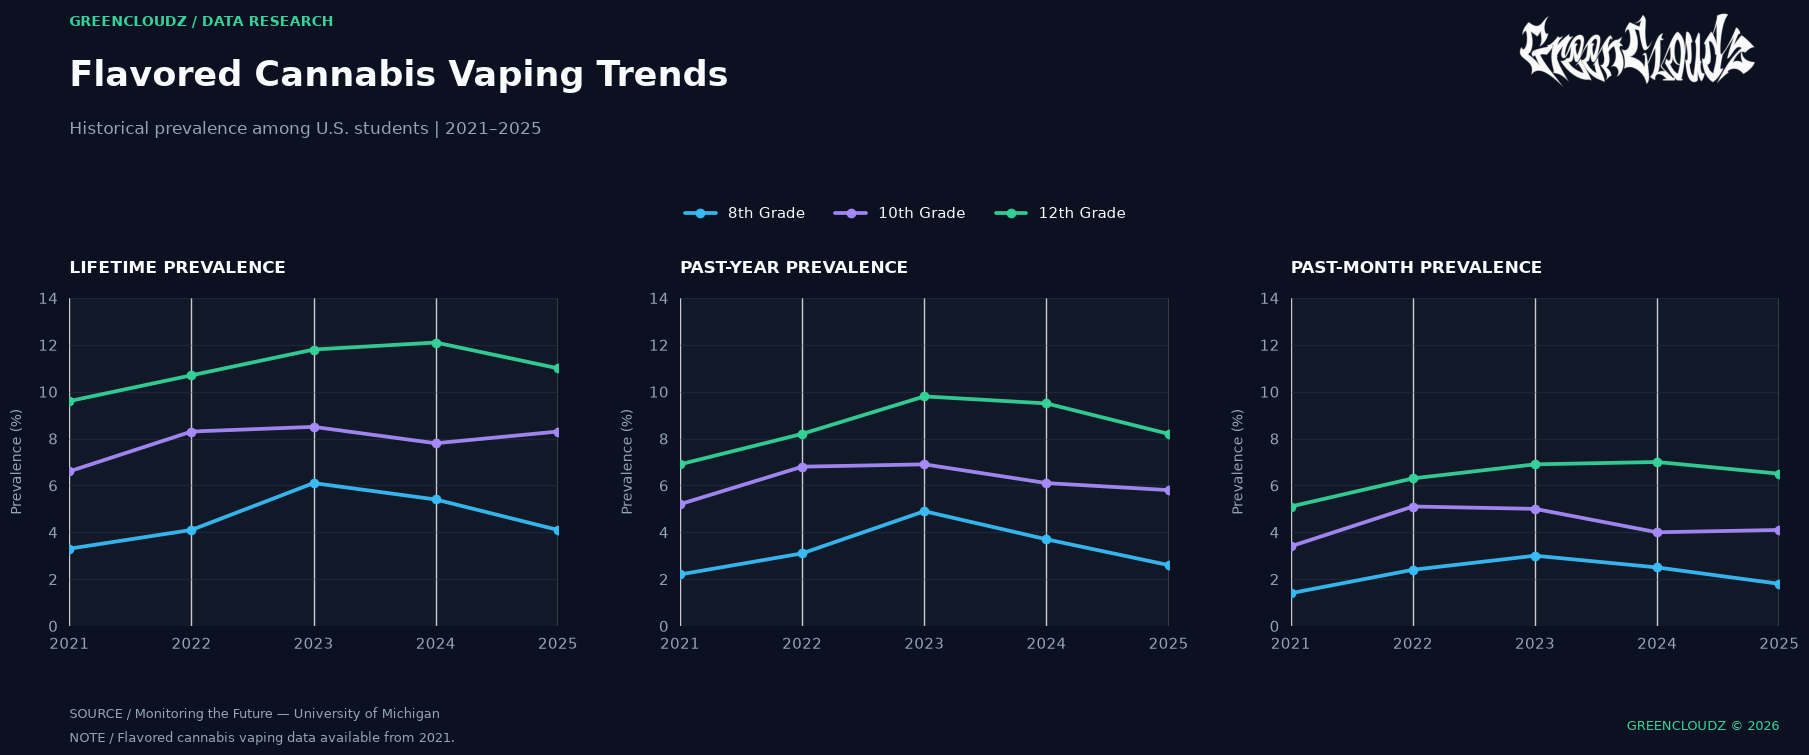

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

GRADE_COLORS = {
    "8th Grade": "#38BDF8",
    "10th Grade": "#A78BFA",
    "12th Grade": "#34D399"
}

# Configure typography
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path(
    "../data/processed/cannabis_prevalence_clean.csv"
)

df = pd.read_csv(DATA_PATH)

flavored_data = df[
    df["drug"] == "Vaping Flavored Cannabis"
].copy()

intervals = ["Lifetime", "12 Month", "30 Day"]
grades = ["8th Grade", "10th Grade", "12th Grade"]

interval_titles = {
    "Lifetime": "LIFETIME PREVALENCE",
    "12 Month": "PAST-YEAR PREVALENCE",
    "30 Day": "PAST-MONTH PREVALENCE"
}

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 8),
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.06,
    right=0.96,
    top=0.60,
    bottom=0.19,
    wspace=0.25
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.06, 0.94,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.06, 0.865,
    "Flavored Cannabis Vaping Trends",
    fontsize=25,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.06, 0.805,
    "Historical prevalence among U.S. students | 2021–2025",
    fontsize=12,
    color=COLORS["muted"]
)

# --------------------------------------------------
# HISTORICAL VISUALIZATION
# --------------------------------------------------

for ax, interval in zip(axes, intervals):

    ax.set_facecolor(COLORS["panel"])

    interval_data = flavored_data[
        flavored_data["time"] == interval
    ]

    for grade in grades:

        series = interval_data[
            interval_data["grade"] == grade
        ].sort_values("year")

        ax.plot(
            series["year"],
            series["estimate"],
            label=grade,
            color=GRADE_COLORS[grade],
            linewidth=2.7,
            marker="o",
            markersize=6,
            alpha=0.95
        )

    ax.set_title(
        interval_titles[interval],
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=COLORS["text"],
        pad=18
    )

    ax.set_xlim(2021, 2025)
    ax.set_xticks(range(2021, 2026))

    ax.set_ylim(0, 14)
    ax.set_yticks(range(0, 15, 2))

    ax.set_ylabel(
        "Prevalence (%)",
        fontsize=10,
        labelpad=10
    )

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        alpha=0.35
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        length=0,
        pad=8
    )

# --------------------------------------------------
# SHARED LEGEND
# --------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center",
    bbox_to_anchor=(0.50, 0.705),
    ncol=3,
    frameon=False,
    labelcolor=COLORS["text"],
    fontsize=11
)

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.81, 0.86, 0.15, 0.10
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.06, 0.075,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.06, 0.045,
    "NOTE / Flavored cannabis vaping data available from 2021.",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.96, 0.06,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "flavored_cannabis_vaping_trends.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

### 8.3 Flavored Cannabis Vaping: Historical Change Assessment

This section quantifies changes in flavored cannabis vaping prevalence between 2021 and 2025.

**Research Objectives:**

- Calculate absolute prevalence changes in percentage points.
- Calculate relative percentage changes.
- Identify historical maximum and minimum prevalence estimates.
- Compare changes across educational grades and reporting intervals.

**Metrics:**

- Baseline prevalence (2021).
- Final prevalence (2025).
- Absolute change (percentage points).
- Relative change (%).
- Historical maximum and minimum prevalence.

**Methodological Considerations:**

The analysis uses a common five-year observation period across all reporting intervals and educational grades.

Relative changes must be interpreted alongside absolute changes, particularly when baseline prevalence is low.

Historical differences describe changes in survey estimates and do not establish statistical significance.

In [18]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter flavored cannabis vaping observations
flavored_data = df[
    df["drug"] == "Vaping Flavored Cannabis"
].copy()

# Define comparison period
BASELINE_YEAR = 2021
FINAL_YEAR = 2025

# Calculate historical metrics
results = []

for (interval, grade), group in flavored_data.groupby(["time", "grade"]):

    group = group.sort_values("year")

    baseline = group.loc[
        group["year"] == BASELINE_YEAR, "estimate"
    ].iloc[0]

    final = group.loc[
        group["year"] == FINAL_YEAR, "estimate"
    ].iloc[0]

    peak = group.loc[group["estimate"].idxmax()]
    minimum = group.loc[group["estimate"].idxmin()]

    absolute_change = final - baseline

    relative_change = (
        (absolute_change / baseline) * 100
        if baseline != 0 else float("nan")
    )

    results.append({
        "Interval": interval,
        "Grade": grade,
        "2021 Prevalence (%)": baseline,
        "2025 Prevalence (%)": final,
        "Absolute Change (pp)": absolute_change,
        "Relative Change (%)": relative_change,
        "Peak Year": int(peak["year"]),
        "Peak Prevalence (%)": peak["estimate"],
        "Minimum Year": int(minimum["year"]),
        "Minimum Prevalence (%)": minimum["estimate"]
    })

# Create summary table
flavored_summary = pd.DataFrame(results)

# Define reporting interval and grade order
interval_order = ["Lifetime", "12 Month", "30 Day"]
grade_order = ["8th Grade", "10th Grade", "12th Grade"]

flavored_summary["Interval"] = pd.Categorical(
    flavored_summary["Interval"],
    categories=interval_order,
    ordered=True
)

flavored_summary["Grade"] = pd.Categorical(
    flavored_summary["Grade"],
    categories=grade_order,
    ordered=True
)

# Sort and display results
flavored_summary = flavored_summary.sort_values(
    ["Interval", "Grade"]
).reset_index(drop=True)

display(flavored_summary.round(2))

,Interval,Grade,2021 Prevalence (%),2025 Prevalence (%),Absolute Change (pp),Relative Change (%),Peak Year,Peak Prevalence (%),Minimum Year,Minimum Prevalence (%)
0,Lifetime,8th Grade,3.3,4.1,0.8,24.24,2023,6.1,2021,3.3
1,Lifetime,10th Grade,6.6,8.3,1.7,25.76,2023,8.5,2021,6.6
2,Lifetime,12th Grade,9.6,11.0,1.4,14.58,2024,12.1,2021,9.6
3,12 Month,8th Grade,2.2,2.6,0.4,18.18,2023,4.9,2021,2.2
4,12 Month,10th Grade,5.2,5.8,0.6,11.54,2023,6.9,2021,5.2
5,12 Month,12th Grade,6.9,8.2,1.3,18.84,2023,9.8,2021,6.9
6,30 Day,8th Grade,1.4,1.8,0.4,28.57,2023,3.0,2021,1.4
7,30 Day,10th Grade,3.4,4.1,0.7,20.59,2022,5.1,2021,3.4
8,30 Day,12th Grade,5.1,6.5,1.4,27.45,2024,7.0,2021,5.1


### 8.4 Flavored Cannabis Vaping: Key Findings

**Finding 1 — Increased prevalence across all indicators**

All nine grade-by-interval combinations recorded higher prevalence estimates in 2025 than in 2021.

Absolute increases ranged from 0.4 to 1.7 percentage points.

**Finding 2 — Lifetime prevalence**

Lifetime prevalence increased across all educational grades:

- 8th Grade: 3.3% to 4.1% (+0.8 pp).
- 10th Grade: 6.6% to 8.3% (+1.7 pp).
- 12th Grade: 9.6% to 11.0% (+1.4 pp).

The largest absolute increase occurred among 10th-grade students.

**Finding 3 — Past-year and past-month prevalence**

Among 12th-grade students:

- Past-year prevalence increased from 6.9% to 8.2%.
- Past-month prevalence increased from 5.1% to 6.5%.

These represent absolute increases of 1.3 and 1.4 percentage points, respectively.

**Finding 4 — Historical peaks**

All nine indicators reached their maximum recorded prevalence between 2022 and 2024.

None reached its maximum in 2025.

**Interpretation**

Flavored cannabis vaping prevalence increased between 2021 and 2025 across all available reporting intervals and educational grades.

However, several indicators declined after reaching historical peaks, suggesting that short-term fluctuations differ from overall changes between the first and final observations.

**Limitations**

- The dataset covers only five years.
- Reporting intervals represent overlapping populations.
- Changes in survey estimates have not been tested for statistical significance.
- The analysis does not establish causal relationships.

## 9. CBD Consumption Analysis

### 9.1 Dataset Overview and Historical Coverage

This section examines reported CBD use prevalence among U.S. students between 2023 and 2024.

**Research Question (RQ5):**

How did past-year CBD use prevalence change across educational grades between 2023 and 2024?

**Analytical Objectives:**

1. Compare CBD prevalence between 2023 and 2024.
2. Identify differences across educational grades.
3. Calculate absolute and relative prevalence changes.
4. Assess the limitations of analyzing a short observation period.

**Available Data:**

- Substance: CBD (Cannabidiol).
- Reporting Interval: Past 12 Months.
- Educational Grades: 8th, 10th, and 12th.
- Observation Period: 2023–2024.
- Total Observations: 6.

**Methodological Considerations:**

Two annual observations are insufficient to establish a long-term trend.

The analysis focuses on descriptive differences between survey estimates.

CBD use must not be interpreted as equivalent to THC-containing cannabis use.

In [19]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Filter CBD observations
cbd_data = df[
    (df["drug"] == "CBD") &
    (df["time"] == "12 Month")
].copy()

# Reshape data for annual comparison
cbd_comparison = cbd_data.pivot(
    index="grade",
    columns="year",
    values="estimate"
)

# Rename columns
cbd_comparison = cbd_comparison.rename(
    columns={
        2023: "2023 Prevalence (%)",
        2024: "2024 Prevalence (%)"
    }
)

# Calculate absolute change
cbd_comparison["Absolute Change (pp)"] = (
    cbd_comparison["2024 Prevalence (%)"]
    - cbd_comparison["2023 Prevalence (%)"]
)

# Calculate relative change
cbd_comparison["Relative Change (%)"] = (
    cbd_comparison["Absolute Change (pp)"]
    / cbd_comparison["2023 Prevalence (%)"]
) * 100

# Organize educational grades
grade_order = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

cbd_comparison = cbd_comparison.reindex(grade_order)

# Display results
print("CBD PREVALENCE COMPARISON | 2023–2024")
display(cbd_comparison.round(2))

CBD PREVALENCE COMPARISON | 2023–2024


year,2023 Prevalence (%),2024 Prevalence (%),Absolute Change (pp),Relative Change (%)
grade,,,,
8th Grade,5.0,3.3,-1.7,-34.00
10th Grade,11.8,8.3,-3.5,-29.66
12th Grade,15.8,13.3,-2.5,-15.82


### 9.2 CBD Prevalence Comparison (2023–2024)

This visualization compares past-year CBD use prevalence among U.S. students in 2023 and 2024.

**Research Objectives:**

- Compare prevalence estimates between consecutive years.
- Identify differences across educational grades.
- Visualize the magnitude of observed changes.

**Visualization Design:**

Grouped bars represent 2023 and 2024 prevalence estimates for each educational grade.

The vertical axis represents past-year prevalence (%).

**Methodological Note:**

The visualization presents descriptive differences between two survey years. It does not establish long-term trends or statistical significance.

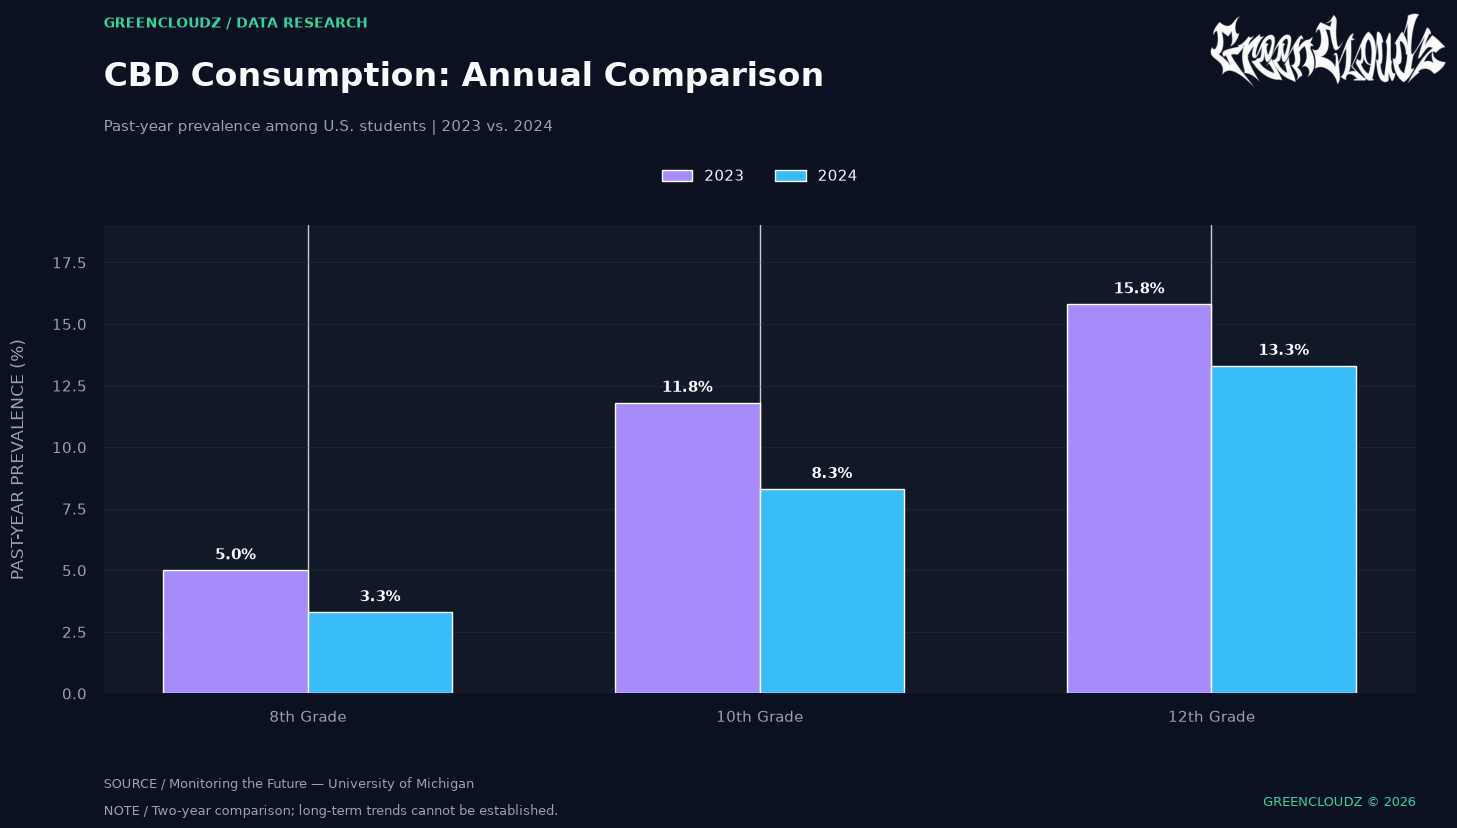

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399",
    "year_2023": "#A78BFA",
    "year_2024": "#38BDF8"
}

available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path(
    "../data/processed/cannabis_prevalence_clean.csv"
)

df = pd.read_csv(DATA_PATH)

cbd_data = df[
    (df["drug"] == "CBD") &
    (df["time"] == "12 Month")
].copy()

grade_order = ["8th Grade", "10th Grade", "12th Grade"]

cbd_pivot = cbd_data.pivot(
    index="grade",
    columns="year",
    values="estimate"
).reindex(grade_order)

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig = plt.figure(
    figsize=(16, 9),
    facecolor=COLORS["background"]
)

ax = fig.add_axes(
    [0.10, 0.20, 0.82, 0.52],
    facecolor=COLORS["panel"]
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.10, 0.94,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.10, 0.875,
    "CBD Consumption: Annual Comparison",
    fontsize=24,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.10, 0.825,
    "Past-year prevalence among U.S. students | 2023 vs. 2024",
    fontsize=11,
    color=COLORS["muted"]
)

# --------------------------------------------------
# GROUPED BAR CHART
# --------------------------------------------------

import numpy as np

positions = np.arange(len(grade_order))
bar_width = 0.32

bars_2023 = ax.bar(
    positions - bar_width / 2,
    cbd_pivot[2023],
    width=bar_width,
    color=COLORS["year_2023"],
    label="2023",
    zorder=3
)

bars_2024 = ax.bar(
    positions + bar_width / 2,
    cbd_pivot[2024],
    width=bar_width,
    color=COLORS["year_2024"],
    label="2024",
    zorder=3
)

# Add value labels
for bars in [bars_2023, bars_2024]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{bar.get_height():.1f}%",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color=COLORS["text"]
        )

# --------------------------------------------------
# AXIS STYLING
# --------------------------------------------------

ax.set_xticks(positions)
ax.set_xticklabels(grade_order)

ax.set_ylim(0, 19)
ax.set_ylabel("PAST-YEAR PREVALENCE (%)", labelpad=18)

ax.grid(
    axis="y",
    color=COLORS["grid"],
    alpha=0.30
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="both", length=0, pad=12)

# Configure legend
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=2,
    frameon=False,
    labelcolor=COLORS["text"],
    fontsize=11
)

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():
    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.79, 0.87, 0.15, 0.09
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.10, 0.095,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.10, 0.065,
    "NOTE / Two-year comparison; long-term trends cannot be established.",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.92, 0.075,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "cbd_prevalence_comparison.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

### 9.3 CBD Consumption: Key Findings

**Finding 1 — Declining prevalence across all grades**

Past-year CBD use prevalence decreased between 2023 and 2024 across all three educational grades.

- 8th Grade: 5.0% to 3.3% (−1.7 percentage points).
- 10th Grade: 11.8% to 8.3% (−3.5 percentage points).
- 12th Grade: 15.8% to 13.3% (−2.5 percentage points).

**Finding 2 — Largest absolute decline**

The largest absolute decrease occurred among 10th-grade students, with a reduction of 3.5 percentage points.

**Finding 3 — Largest relative decline**

The largest relative decrease occurred among 8th-grade students, representing a 34.0% reduction compared with 2023.

**Finding 4 — Differences across educational grades**

Despite declining prevalence, 12th-grade students maintained the highest reported CBD use prevalence in both years.

**Interpretation**

The results indicate a decline in reported past-year CBD use prevalence across all three educational grades between 2023 and 2024.

However, these observations are insufficient to establish whether CBD consumption is experiencing a sustained long-term decline.

**Limitations**

- Only two survey years are available.
- Differences have not been evaluated for statistical significance.
- CBD consumption should not be interpreted as equivalent to THC-containing cannabis consumption.
- The analysis does not establish the causes of the observed changes.

## 10. Cross-Category Comparative Analysis

### 10.1 Comparable Consumption Indicators

This section compares cannabis-related product categories using consistent reporting intervals, educational grades, and survey years.

**Research Question (RQ6):**

How do cannabis-related consumption patterns differ across product categories among U.S. students?

**Analytical Objectives:**

1. Compare prevalence across cannabis product categories.
2. Identify differences between educational grades.
3. Examine whether product categories follow similar historical patterns.
4. Identify opportunities for further statistical investigation.

**Comparison Criteria:**

- Same survey year.
- Same educational grade.
- Same reporting interval.
- Clearly defined product category.

**Methodological Considerations:**

Cannabis-related categories are not mutually exclusive. Students may report using multiple products.

Therefore, prevalence estimates must not be added together.

Differences between categories describe population-level prevalence estimates and do not establish causal relationships.

Cross-category comparisons must also consider differences in survey questions and measurement definitions.

In [21]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Define comparison parameters
COMPARISON_YEAR = 2024
REPORTING_INTERVAL = "12 Month"

PRODUCT_CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis",
    "CBD"
]

GRADE_ORDER = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
comparison_data = df[
    (df["year"] == COMPARISON_YEAR) &
    (df["time"] == REPORTING_INTERVAL) &
    (df["drug"].isin(PRODUCT_CATEGORIES))
].copy()

# Create comparison table
category_comparison = comparison_data.pivot(
    index="grade",
    columns="drug",
    values="estimate"
)

# Organize rows and columns
category_comparison = category_comparison.reindex(
    index=GRADE_ORDER,
    columns=PRODUCT_CATEGORIES
)

# Validate comparison completeness
expected_observations = len(GRADE_ORDER) * len(PRODUCT_CATEGORIES)

print(f"Comparison year: {COMPARISON_YEAR}")
print(f"Reporting interval: {REPORTING_INTERVAL}")
print(f"Expected observations: {expected_observations}")
print(f"Available observations: {len(comparison_data)}")
print(f"Missing comparison values: {category_comparison.isna().sum().sum()}")

display(category_comparison.round(2))

Comparison year: 2024
Reporting interval: 12 Month
Expected observations: 12
Available observations: 12
Missing comparison values: 0


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis,CBD
grade,,,,
8th Grade,9.1,5.6,3.7,3.3
10th Grade,15.9,11.6,6.1,8.3
12th Grade,25.8,17.6,9.5,13.3


### 10.2 Cannabis Product Prevalence Comparison — 2024

This visualization compares past-year prevalence estimates across four cannabis-related categories and three educational grades.

**Research Objective:** Identify differences in reported product use across educational grades during the same survey year.

**Comparison Parameters:**

- Survey year: 2024.
- Reporting interval: Past 12 months.
- Population: U.S. students in 8th, 10th, and 12th grades.

**Methodological Note:** Product categories may overlap. The percentages must not be added together or interpreted as mutually exclusive population groups.

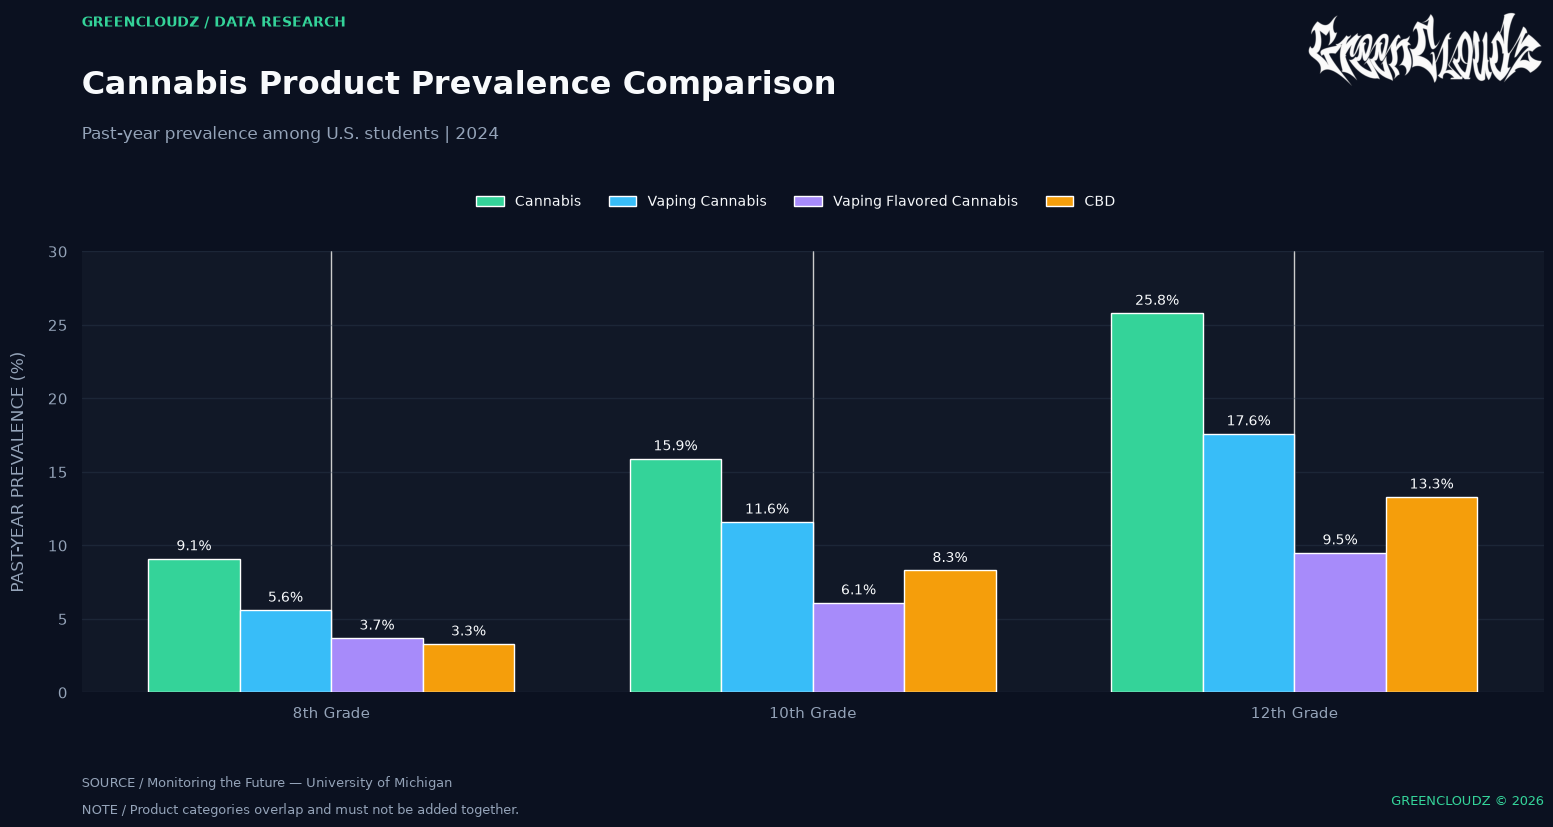

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define comparison parameters
COMPARISON_YEAR = 2024
GRADE_ORDER = ["8th Grade", "10th Grade", "12th Grade"]

PRODUCT_CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis",
    "CBD"
]

# Prepare comparison data
comparison_data = df[
    (df["year"] == COMPARISON_YEAR)
    & (df["time"] == "12 Month")
    & (df["drug"].isin(PRODUCT_CATEGORIES))
]

category_comparison = comparison_data.pivot(
    index="grade",
    columns="drug",
    values="estimate"
).reindex(
    index=GRADE_ORDER,
    columns=PRODUCT_CATEGORIES
)

assert not category_comparison.isna().any().any(), (
    "Missing values detected in the comparison dataset."
)

# Define Greencloudz visual identity
COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

PRODUCT_COLORS = {
    "Cannabis": "#34D399",
    "Vaping Cannabis": "#38BDF8",
    "Vaping Flavored Cannabis": "#A78BFA",
    "CBD": "#F59E0B"
}

# Create figure
fig = plt.figure(figsize=(17, 9), facecolor=COLORS["background"])

ax = fig.add_axes(
    [0.08, 0.20, 0.86, 0.49],
    facecolor=COLORS["panel"]
)

# Add header
fig.text(
    0.08, 0.94,
    "GREENCLOUDZ / DATA RESEARCH",
    color=COLORS["accent"],
    fontsize=10,
    fontweight="bold"
)

fig.text(
    0.08, 0.865,
    "Cannabis Product Prevalence Comparison",
    color=COLORS["text"],
    fontsize=23,
    fontweight="bold"
)

fig.text(
    0.08, 0.815,
    "Past-year prevalence among U.S. students | 2024",
    color=COLORS["muted"],
    fontsize=12
)

# Plot grouped bars
positions = np.arange(len(GRADE_ORDER))
bar_width = 0.19

for index, product in enumerate(PRODUCT_CATEGORIES):

    offset = (index - 1.5) * bar_width

    bars = ax.bar(
        positions + offset,
        category_comparison[product],
        width=bar_width,
        label=product,
        color=PRODUCT_COLORS[product],
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.35,
            f"{bar.get_height():.1f}%",
            ha="center",
            va="bottom",
            color=COLORS["text"],
            fontsize=10
        )

# Configure axes
ax.set_xticks(positions)
ax.set_xticklabels(GRADE_ORDER)

ax.set_ylim(0, 30)
ax.set_ylabel(
    "PAST-YEAR PREVALENCE (%)",
    color=COLORS["muted"],
    labelpad=15
)

ax.tick_params(
    axis="both",
    colors=COLORS["muted"],
    length=0,
    pad=10
)

ax.grid(
    axis="y",
    color=COLORS["grid"],
    alpha=0.35
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

# Position legend
legend = fig.legend(
    *ax.get_legend_handles_labels(),
    loc="center",
    bbox_to_anchor=(0.50, 0.745),
    ncol=4,
    frameon=False,
    fontsize=10
)

for label in legend.get_texts():
    label.set_color(COLORS["text"])

# Add Greencloudz logo
logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.80, 0.87, 0.14, 0.09
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# Add footer
fig.text(
    0.08, 0.095,
    "SOURCE / Monitoring the Future — University of Michigan",
    color=COLORS["muted"],
    fontsize=9
)

fig.text(
    0.08, 0.065,
    "NOTE / Product categories overlap and must not be added together.",
    color=COLORS["muted"],
    fontsize=9
)

fig.text(
    0.94, 0.075,
    "GREENCLOUDZ © 2026",
    color=COLORS["accent"],
    fontsize=9,
    ha="right"
)

# Export figure
OUTPUT_PATH = Path("../reports/figures")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_PATH / "cannabis_product_comparison_2024.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

### 10.3 Cross-Category Comparison: Key Findings

**Finding 1 — Higher prevalence among older students**

In 2024, 12th-grade students recorded the highest past-year prevalence estimates across all four cannabis-related categories.

**Finding 2 — General cannabis use**

Cannabis recorded the highest prevalence estimates across all educational grades:

- 8th Grade: 9.1%.
- 10th Grade: 15.9%.
- 12th Grade: 25.8%.

**Finding 3 — Cannabis vaping**

Cannabis vaping was reported by:

- 5.6% of 8th-grade students.
- 11.6% of 10th-grade students.
- 17.6% of 12th-grade students.

**Finding 4 — CBD and flavored cannabis vaping**

CBD prevalence exceeded flavored cannabis vaping prevalence among 10th- and 12th-grade students.

Among 8th-grade students, flavored cannabis vaping prevalence was slightly higher than CBD prevalence.

**Interpretation**

The results demonstrate differences in reported cannabis-related product use across educational grades.

However, these categories represent overlapping populations and should not be interpreted as mutually exclusive groups.

**Limitations**

- Comparisons are restricted to 2024.
- Medical cannabis is excluded because comparable past-year estimates are unavailable.
- Differences have not been evaluated for statistical significance.
- Survey question definitions may differ across product categories.

In [23]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define comparison parameters
START_YEAR = 2021
END_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
trend_data = df[
    (df["drug"].isin(CATEGORIES)) &
    (df["time"] == "12 Month") &
    (df["year"].between(START_YEAR, END_YEAR))
].copy()

# Validate the expected combinations
expected_index = pd.MultiIndex.from_product(
    [CATEGORIES, GRADES, range(START_YEAR, END_YEAR + 1)],
    names=["drug", "grade", "year"]
)

actual_index = pd.MultiIndex.from_frame(
    trend_data[["drug", "grade", "year"]]
)

missing_combinations = expected_index.difference(actual_index)

duplicate_count = trend_data.duplicated(
    subset=["drug", "grade", "year"]
).sum()

print(f"Total observations: {len(trend_data)}")
print(f"Expected observations: {len(expected_index)}")
print(f"Missing combinations: {len(missing_combinations)}")
print(f"Duplicate observations: {duplicate_count}")

assert len(missing_combinations) == 0
assert duplicate_count == 0

display(
    trend_data.pivot_table(
        index=["year", "grade"],
        columns="drug",
        values="estimate"
    ).round(2)
)

Total observations: 45
Expected observations: 45
Missing combinations: 0
Duplicate observations: 0


drug             Cannabis  Vaping Cannabis  Vaping Flavored Cannabis
year grade                                                          
2021 10th Grade      17.3             12.4                       5.2
     12th Grade      30.5             18.3                       6.9
     8th Grade        7.1              4.7                       2.2
2022 10th Grade      19.5             15.0                       6.8
     12th Grade      30.7             20.6                       8.2
     8th Grade        8.3              6.0                       3.1
2023 10th Grade      17.8             13.1                       6.9
     12th Grade      29.0             19.6                       9.8
     8th Grade        8.3              6.5                       4.9
2024 10th Grade      15.9             11.6                       6.1
     12th Grade      25.8             17.6                       9.5
     8th Grade        9.1              5.6                       3.7
2025 10th Grade      15.6             10.6                       5.8
     12th Grade      25.7             16.0                       8.2
     8th Grade        7.6              4.7                       2.6

### 10.5 Annual Prevalence Comparison by Product Category

The following visualization compares annual past-year prevalence estimates across three cannabis-related categories.

Each panel represents an educational grade, allowing differences between product categories to be examined within the same student population.

**Visualization Design:**

- Three panels, one per educational grade.
- Three lines per panel, one per product category.
- Common observation period: 2021–2025.
- Consistent percentage scale across all panels.
- Original annual survey estimates without interpolation.

**Interpretation Note:**

Cannabis vaping and flavored cannabis vaping may overlap with general cannabis use.

The visualization compares prevalence estimates, not independent consumer populations.

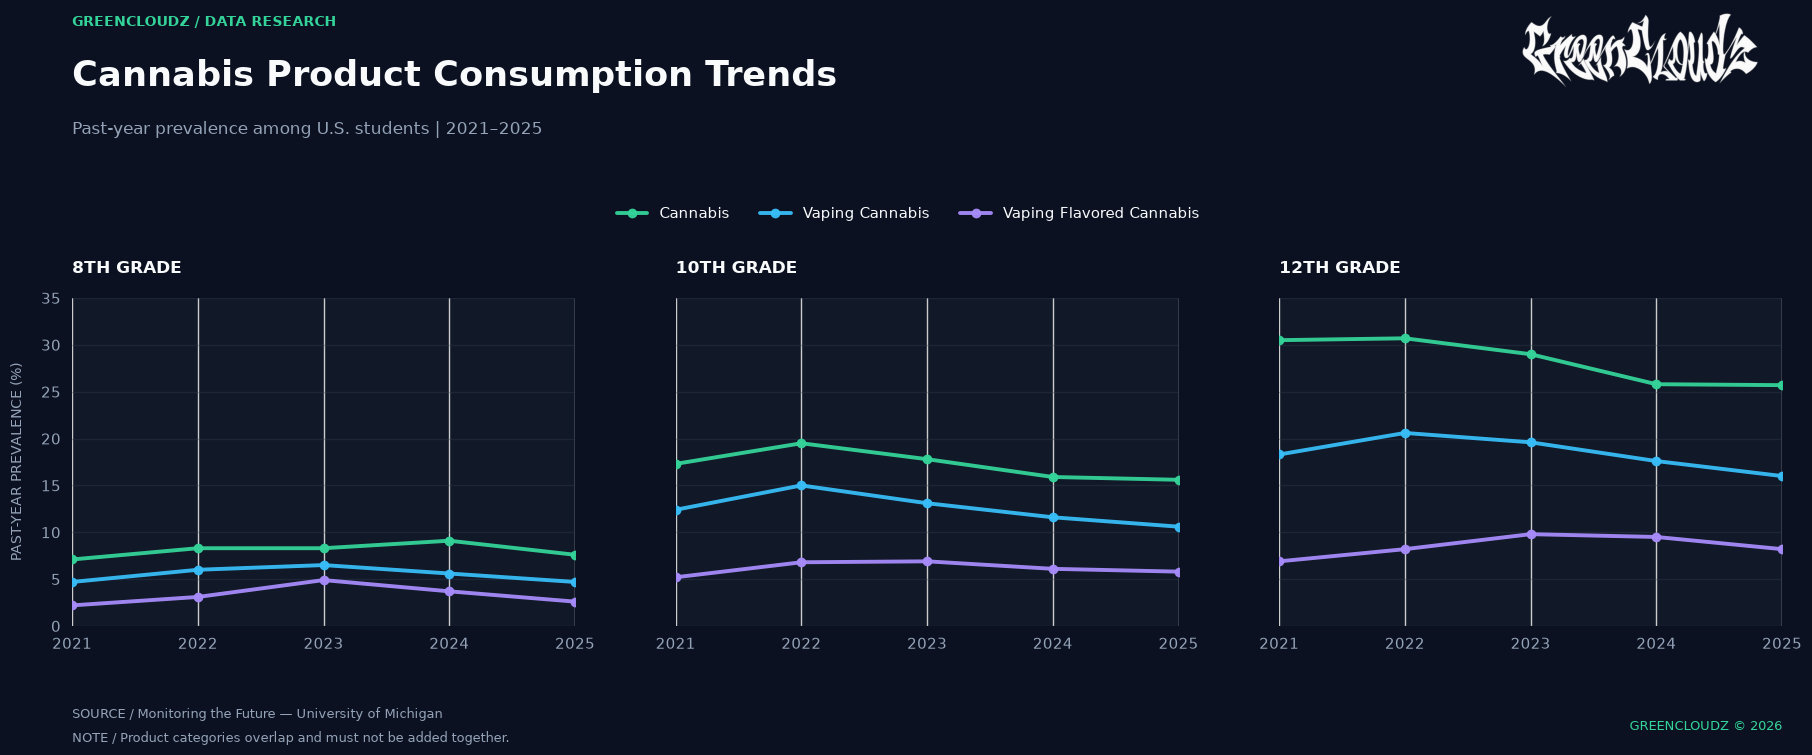

In [24]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pathlib import Path

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

PRODUCT_COLORS = {
    "Cannabis": "#34D399",
    "Vaping Cannabis": "#38BDF8",
    "Vaping Flavored Cannabis": "#A78BFA"
}

available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

categories = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

grades = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

trend_data = df[
    (df["drug"].isin(categories)) &
    (df["time"] == "12 Month") &
    (df["year"].between(2021, 2025))
].copy()

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 8),
    sharey=True,
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.06,
    right=0.96,
    top=0.60,
    bottom=0.19,
    wspace=0.20
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.06, 0.94,
    "GREENCLOUDZ / DATA RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.06, 0.865,
    "Cannabis Product Consumption Trends",
    fontsize=25,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.06, 0.805,
    "Past-year prevalence among U.S. students | 2021–2025",
    fontsize=12,
    color=COLORS["muted"]
)

# --------------------------------------------------
# HISTORICAL VISUALIZATION
# --------------------------------------------------

for ax, grade in zip(axes, grades):

    ax.set_facecolor(COLORS["panel"])

    grade_data = trend_data[
        trend_data["grade"] == grade
    ]

    for category in categories:

        series = grade_data[
            grade_data["drug"] == category
        ].sort_values("year")

        ax.plot(
            series["year"],
            series["estimate"],
            label=category,
            color=PRODUCT_COLORS[category],
            linewidth=2.8,
            marker="o",
            markersize=6,
            alpha=0.95
        )

    ax.set_title(
        grade.upper(),
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=COLORS["text"],
        pad=18
    )

    ax.set_xlim(2021, 2025)
    ax.set_xticks(range(2021, 2026))

    ax.set_ylim(0, 35)
    ax.set_yticks(range(0, 36, 5))

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        alpha=0.35
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        colors=COLORS["muted"],
        length=0,
        pad=8
    )

axes[0].set_ylabel(
    "PAST-YEAR PREVALENCE (%)",
    fontsize=10,
    labelpad=12
)

# --------------------------------------------------
# SHARED LEGEND
# --------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

legend = fig.legend(
    handles,
    labels,
    loc="center",
    bbox_to_anchor=(0.50, 0.705),
    ncol=3,
    frameon=False,
    fontsize=11
)

for label in legend.get_texts():
    label.set_color(COLORS["text"])

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():
    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.81, 0.86, 0.15, 0.10
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.06, 0.075,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.06, 0.045,
    "NOTE / Product categories overlap and must not be added together.",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.96, 0.06,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

output_path = Path("../reports/figures")
output_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path / "cannabis_product_trends_2021_2025.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

### 10.6 Cross-Category Historical Change Assessment

This section quantifies changes in past-year cannabis use prevalence across three product categories between 2021 and 2025.

**Research Objectives:**

- Calculate absolute prevalence changes in percentage points.
- Calculate relative percentage changes.
- Identify historical maximum and minimum estimates.
- Compare changes across product categories and educational grades.

**Comparison Parameters:**

- Baseline year: 2021.
- Final year: 2025.
- Reporting interval: Past 12 months.
- Population: U.S. students in 8th, 10th, and 12th grades.

**Methodological Considerations:**

All comparisons use the same observation period and reporting interval.

Product categories may overlap and must not be interpreted as mutually exclusive populations.

The calculations describe changes in survey estimates, not statistically significant differences.

In [25]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define comparison parameters
BASELINE_YEAR = 2021
FINAL_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
comparison_data = df[
    (df["drug"].isin(CATEGORIES)) &
    (df["time"] == "12 Month") &
    (df["year"].between(BASELINE_YEAR, FINAL_YEAR))
].copy()

# Calculate historical changes
results = []

for (category, grade), group in comparison_data.groupby(
    ["drug", "grade"]
):
    group = group.sort_values("year")

    baseline = group.loc[
        group["year"] == BASELINE_YEAR, "estimate"
    ].iloc[0]

    final = group.loc[
        group["year"] == FINAL_YEAR, "estimate"
    ].iloc[0]

    peak = group.loc[group["estimate"].idxmax()]
    minimum = group.loc[group["estimate"].idxmin()]

    absolute_change = final - baseline

    relative_change = (
        (absolute_change / baseline) * 100
        if baseline != 0 else float("nan")
    )

    results.append({
        "Category": category,
        "Grade": grade,
        "2021 Prevalence (%)": baseline,
        "2025 Prevalence (%)": final,
        "Absolute Change (pp)": absolute_change,
        "Relative Change (%)": relative_change,
        "Peak Year": int(peak["year"]),
        "Peak Prevalence (%)": peak["estimate"],
        "Minimum Year": int(minimum["year"]),
        "Minimum Prevalence (%)": minimum["estimate"]
    })

# Create summary table
category_summary = pd.DataFrame(results)

# Organize categories and grades
category_summary["Category"] = pd.Categorical(
    category_summary["Category"],
    categories=CATEGORIES,
    ordered=True
)

category_summary["Grade"] = pd.Categorical(
    category_summary["Grade"],
    categories=GRADES,
    ordered=True
)

category_summary = category_summary.sort_values(
    ["Category", "Grade"]
).reset_index(drop=True)

# Display results
display(category_summary.round(2))

,Category,Grade,2021 Prevalence (%),2025 Prevalence (%),Absolute Change (pp),Relative Change (%),Peak Year,Peak Prevalence (%),Minimum Year,Minimum Prevalence (%)
0,Cannabis,8th Grade,7.1,7.6,0.5,7.04,2024,9.1,2021,7.1
1,Cannabis,10th Grade,17.3,15.6,-1.7,-9.83,2022,19.5,2025,15.6
2,Cannabis,12th Grade,30.5,25.7,-4.8,-15.74,2022,30.7,2025,25.7
3,Vaping Cannabis,8th Grade,4.7,4.7,0.0,0.00,2023,6.5,2021,4.7
4,Vaping Cannabis,10th Grade,12.4,10.6,-1.8,-14.52,2022,15.0,2025,10.6
5,Vaping Cannabis,12th Grade,18.3,16.0,-2.3,-12.57,2022,20.6,2025,16.0
6,Vaping Flavored Cannabis,8th Grade,2.2,2.6,0.4,18.18,2023,4.9,2021,2.2
7,Vaping Flavored Cannabis,10th Grade,5.2,5.8,0.6,11.54,2023,6.9,2021,5.2
8,Vaping Flavored Cannabis,12th Grade,6.9,8.2,1.3,18.84,2023,9.8,2021,6.9


### 10.7 Cross-Category Historical Trends: Key Findings

**Finding 1 — General cannabis prevalence declined among older students**

Between 2021 and 2025, past-year cannabis prevalence changed as follows:

- 8th Grade: 7.1% to 7.6% (+0.5 pp).
- 10th Grade: 17.3% to 15.6% (−1.7 pp).
- 12th Grade: 30.5% to 25.7% (−4.8 pp).

The largest absolute decline occurred among 12th-grade students.

**Finding 2 — Cannabis vaping prevalence declined among older students**

Past-year cannabis vaping prevalence decreased among:

- 10th Grade: −1.8 percentage points.
- 12th Grade: −2.3 percentage points.

Among 8th-grade students, prevalence remained at 4.7% in both 2021 and 2025, despite fluctuations during the intervening years.

**Finding 3 — Flavored cannabis vaping prevalence increased across all grades**

Flavored cannabis vaping prevalence increased between 2021 and 2025:

- 8th Grade: +0.4 percentage points.
- 10th Grade: +0.6 percentage points.
- 12th Grade: +1.3 percentage points.

All three grades reached their highest past-year prevalence estimates in 2023.

**Finding 4 — Diverging prevalence patterns**

Among 12th-grade students, general cannabis prevalence declined by 4.8 percentage points, while flavored cannabis vaping prevalence increased by 1.3 percentage points.

These differences suggest that cannabis-related product categories did not follow identical historical trajectories.

**Interpretation**

The results demonstrate that changes in cannabis use prevalence vary depending on the product category and educational grade.

However, the observed differences do not establish substitution between consumption methods.

**Limitations**

- Product categories represent overlapping populations.
- Only five survey years are included.
- Survey estimates have not been evaluated for statistical significance.
- The analysis cannot determine individual transitions between consumption methods.
- Observed associations do not establish causal relationships.

## 11. EDA Validation & Methodological Review

### 11.1 Data Integrity Assessment

Before proceeding to statistical analysis, the exploratory findings must be evaluated for methodological consistency and data integrity.

**Validation Objectives:**

1. Verify dataset completeness and uniqueness.
2. Validate prevalence estimates and reporting intervals.
3. Identify missing years within historical series.
4. Examine consistency across consumption indicators.
5. Assess the limitations of cross-category comparisons.

**Validation Criteria:**

- Prevalence estimates must range between 0% and 100%.
- Each combination of substance, reporting interval, educational grade, and year must be unique.
- Missing historical observations must not be interpolated.
- Reporting intervals must be interpreted consistently.
- Product categories must not be treated as mutually exclusive.

**Important Distinction:**

Data integrity does not guarantee statistical representativeness or measurement accuracy.

The Monitoring the Future survey methodology, sampling design, and potential sources of uncertainty must also be considered when interpreting results.

In [26]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Define observation identifiers
KEY_COLUMNS = ["drug", "time", "grade", "year"]

# Perform data integrity checks
validation_results = {
    "Total observations": len(df),
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate observations": int(df.duplicated(subset=KEY_COLUMNS).sum()),
    "Invalid prevalence estimates": int(
        (~df["estimate"].between(0, 100)).sum()
    ),
    "Invalid survey years": int(
        (~df["year"].between(1975, 2025)).sum()
    )
}

# Identify missing years within each historical series
missing_years = []

for (drug, interval, grade), group in df.groupby(
    ["drug", "time", "grade"]
):
    observed_years = set(group["year"])

    expected_years = set(
        range(min(observed_years), max(observed_years) + 1)
    )

    for year in sorted(expected_years - observed_years):
        missing_years.append({
            "Category": drug,
            "Interval": interval,
            "Grade": grade,
            "Missing Year": year
        })

# Display validation results
validation_summary = pd.DataFrame(
    validation_results.items(),
    columns=["Validation Check", "Result"]
)

print("DATA INTEGRITY ASSESSMENT")
display(validation_summary)

print("\nHISTORICAL SERIES GAPS")

if missing_years:
    display(pd.DataFrame(missing_years))
else:
    print("No missing years detected within historical series.")

DATA INTEGRITY ASSESSMENT


,Validation Check,Result
0,Total observations,660
1,Missing values,0
2,Duplicate observations,0
3,Invalid prevalence estimates,0
4,Invalid survey years,0



HISTORICAL SERIES GAPS


,Category,Interval,Grade,Missing Year
0,Medical Cannabis,Lifetime,12th Grade,2020


### 11.2 Reporting Interval Consistency

This section evaluates the logical consistency of prevalence estimates across reporting intervals.

**Expected Relationship:**

Lifetime ≥ Past-Year ≥ Past-Month ≥ Daily

This relationship is expected because shorter reporting periods represent subsets of longer reporting periods.

**Validation Objective:**

Identify observations where the reported prevalence estimates violate this expected ordering.

**Methodological Consideration:**

Small inconsistencies may arise from survey estimation, rounding, or differences in measurement definitions.

This check is diagnostic and does not independently establish data accuracy.


In [27]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
df = pd.read_csv(
    "../data/processed/cannabis_prevalence_clean.csv"
)

# Define reporting interval order
intervals = ["Lifetime", "12 Month", "30 Day", "Daily"]

# Reshape prevalence estimates
prevalence_matrix = df.pivot_table(
    index=["drug", "grade", "year"],
    columns="time",
    values="estimate",
    aggfunc="first"
)

# Identify logical inconsistencies
violations = []

for longer, shorter in zip(intervals[:-1], intervals[1:]):

    if longer not in prevalence_matrix or shorter not in prevalence_matrix:
        continue

    comparable = prevalence_matrix[
        [longer, shorter]
    ].dropna()

    invalid = comparable[
        comparable[shorter] > comparable[longer]
    ]

    for index, row in invalid.iterrows():
        violations.append({
            "Category": index[0],
            "Grade": index[1],
            "Year": index[2],
            "Longer Interval": longer,
            "Shorter Interval": shorter,
            "Longer Prevalence (%)": row[longer],
            "Shorter Prevalence (%)": row[shorter]
        })

print(f"Reporting interval violations: {len(violations)}")

if violations:
    display(pd.DataFrame(violations))
else:
    print("All comparable reporting intervals passed validation.")

Reporting interval violations: 0
All comparable reporting intervals passed validation.


### 11.3 Data Quality Validation Results

The processed dataset successfully passed the following integrity checks:

| Validation Check | Result | Status |
|---|---:|---|
| Total observations | 660 | Verified |
| Missing values | 0 | Passed |
| Duplicate observations | 0 | Passed |
| Invalid prevalence estimates | 0 | Passed |
| Invalid survey years | 0 | Passed |
| Reporting interval violations | 0 | Passed |
| Historical series gaps | 1 | Documented |

**Key Findings**

The dataset contains no missing values, duplicate observations, or prevalence estimates outside the valid percentage range.

All comparable reporting intervals satisfy the expected logical ordering:

Lifetime ≥ Past-Year ≥ Past-Month ≥ Daily.

One historical observation is unavailable:

- Category: Medical Cannabis
- Reporting interval: Lifetime
- Educational grade: 12th Grade
- Missing year: 2020

No interpolation or imputation was performed.

**Methodological Limitations**

These checks establish structural consistency but do not independently verify the accuracy of the original survey estimates.

Additional considerations include:

- Survey sampling uncertainty.
- Potential self-reporting bias.
- Differences in historical survey coverage.
- Changes in survey methodology.
- Differences in measurement definitions across product categories.

**Conclusion**

The processed dataset is suitable for the descriptive analyses conducted in this notebook, subject to the documented methodological limitations.

Statistical inference requires additional consideration of survey design and estimation uncertainty.